# 🚇 Why Does Metro Construction Cost So Much?
### A Global Benchmark of 535 Urban Rail Projects — with an India Lens

**Final Project — Data Analytics using Python** &nbsp;|&nbsp; Pandas · NumPy · Matplotlib · Seaborn · SciPy · scikit-learn

| | |
|---|---|
| **Domain** | Infrastructure & Capital-Project Cost Analytics (Finance / Transportation) |
| **Source** | Transit Costs Project (NYU Marron Institute of Urban Management), curated by TidyTuesday — public GitHub repository, *not* Kaggle |
| **Location** | 56 countries, 6 continents (China, India, Turkey, France, Spain, Japan, USA …) |
| **Timeline** | Projects whose construction mid-point falls between 1987 and 2027 (data compiled up to Jan 2021) |
| **Raw file** | `transit_cost.csv` — 544 rows × 20 columns (535 true projects after cleaning) |
| **Raw data URL** | https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2021/2021-01-05/transit_cost.csv |

---
**How to read this notebook:** every stage has a short *why* before the code and an *interpretation* after every output. The story runs in four stages — **(1)** problem & data → **(2)** cleaning & wrangling → **(3)** statistics & visual analysis → **(4)** insights, recommendations and a decision tool.

# Stage 1 — Problem Definition & Dataset

## 1.1 Business problem
A city transit authority, a state government or an infrastructure investor has to approve a **budget for a new metro line before a single tunnel is dug**. The usual question in the boardroom is: *"Is this estimate reasonable?"* Without a global benchmark of cost **per kilometre**, nobody can answer that with evidence — and cost over-estimates mean fewer lines built for the same public money.

This project builds that benchmark. It answers *what a kilometre of urban rail costs around the world, what drives the difference, and where India sits* — using 535 real projects.

## 1.2 Objectives
1. Keep all project information (country, line, length, tunnelling, stations, timeline, cost) in **one clean, analysis-ready table**.
2. Monitor **cost, length, stations and build time** across projects and over time.
3. Evaluate performance by **country, region, tunnelling share and project size**.
4. Quantify the **drivers of cost per km** with statistical tests (not just charts).
5. Compare **India** with China (the largest builder) and the rest of the world.
6. Convert findings into **recommendations and a budget-benchmark tool** a planner could actually use.

## 1.3 Business questions this notebook answers
| # | Question | Where answered |
|---|---|---|
| Q1 | What does a typical km of metro cost, and how uneven is it? | 3.1 – 3.3, Univariate |
| Q2 | Which countries and regions are cheapest / most expensive? | Bivariate |
| Q3 | How much does going underground add to the cost? | Bivariate, tests |
| Q4 | Have costs risen over time? | Bivariate |
| Q5 | Do longer lines get cheaper per km (economies of scale)? | Bivariate, Multivariate |
| Q6 | Where does India stand against the world? | Deep-dive |

## 1.4 Dataset information & data dictionary
*Original columns are kept in the first table below; cleaner names are introduced in Stage 2 (section 2.3).*

| Original column | Clean name (Stage 2) | Meaning |
|---|---|---|
| `e` | `project_id` | Unique project ID |
| `country` | `country_code` → `country`, `region` | Country code (a few codes, such as `UK`, are non-standard) |
| `city`, `line` | `city`, `line` | City and line/phase name |
| `start_year`, `end_year` | same | Construction start / (planned or actual) end year — stored as **text** with junk values |
| `rr` | `rail_flag` | 0/1 flag; the dataset author himself notes the definition is uncertain → used only as a minor feature |
| `length` | `length_km` | Line length (km) |
| `tunnel_per`, `tunnel` | `tunnel_pct`, `tunnel_km` | Share / length of the line built underground — `tunnel_per` is **text** like `"87.72%"` |
| `stations` | `stations` | Number of passenger stations |
| `cost`, `currency` | `cost_local_m`, `currency` | Cost in millions of local currency |
| `year` | `midpoint_year` | Mid-point year of construction (used for the PPP conversion) |
| `ppp_rate` | `ppp_rate` | Purchasing-power-parity rate at that mid-point year |
| `real_cost` | `cost_usd_m` | Cost in millions of USD (PPP-converted) — stored as **text** |
| `cost_km_millions` | `cost_per_km_usd_m` | **Target metric:** cost per km in millions of USD |
| `source2` | `cost_source` | Where the cost figure came from (Plan / Media / Trade …) |
| `source1`, `reference` | *(dropped)* | Free-text source notes and URLs — not analytical |

**Why this dataset?** It is a real research database (not a textbook toy). It arrives with genuine problems — *text-typed numbers, summary rows pasted into the data, exact duplicates, hidden zeros, contradicting columns and a typo* — which makes the cleaning stage meaningful. It also exceeds the course minimums (500+ rows, 10+ columns, mix of numeric and categorical fields).

## 1.5 Tools & technologies
`Python 3` · `Pandas` & `NumPy` (cleaning, wrangling) · `Matplotlib` & `Seaborn` (visuals) · `SciPy` (statistical tests) · `scikit-learn` (baseline predictive model) · `Google Colab`

## 1.6 Import libraries

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# ---- global look & feel (one consistent style for every chart) ----------
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.labelsize": 11,
    "axes.spines.top": False, "axes.spines.right": False,
})
BLUE, ORANGE, GREY, RED, GREEN = "#2F5D8C", "#E8822E", "#9AA5B1", "#C0392B", "#2E8B57"   # India = orange throughout
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}" if abs(v) >= 10000 else f"{v:.2f}")
RANDOM_STATE = 42

print("pandas", pd.__version__, "| numpy", np.__version__, "| seaborn", sns.__version__)

pandas 3.0.2 | numpy 2.4.4 | seaborn 0.13.2


## 1.7 Load the dataset from GitHub
The raw file is read **directly from the public GitHub repository** so anyone can re-run this notebook without uploading anything. (If GitHub is unreachable, the code falls back to a local copy named `transit_cost.csv`.)

In [2]:
DATA_URL = ("https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/"
            "data/2021/2021-01-05/transit_cost.csv")
try:
    df_raw = pd.read_csv(DATA_URL)
    print("Loaded from GitHub ✔")
except Exception as err:
    print("GitHub load failed →", err, "\nFalling back to local file 'transit_cost.csv'")
    df_raw = pd.read_csv("transit_cost.csv")

print(f"Rows: {df_raw.shape[0]:,} | Columns: {df_raw.shape[1]}")

Loaded from GitHub ✔
Rows: 544 | Columns: 20


## 1.8 Initial EDA — first look at the raw data

In [3]:
df_raw.head()

,e,country,city,line,start_year,end_year,rr,length,tunnel_per,tunnel,stations,source1,cost,currency,year,ppp_rate,real_cost,cost_km_millions,source2,reference
0,7136.00,CA,Vancouver,Broadway,2020,2025,0.00,5.70,87.72%,5.00,6.00,Plan,2830.00,CAD,2018.00,0.84,2377.2,417.05,Media,https://www.translink.ca/Plans-and-Projects/Ra...
1,7137.00,CA,Toronto,Vaughan,2009,2017,0.00,8.60,100.00%,8.60,6.00,Media,3200.00,CAD,2013.00,0.81,2592,301.40,Media,https://www.thestar.com/news/gta/transportatio...
2,7138.00,CA,Toronto,Scarborough,2020,2030,0.00,7.80,100.00%,7.80,3.00,Wiki,5500.00,CAD,2018.00,0.84,4620,592.31,Media,https://urbantoronto.ca/news/2020/03/metrolinx...
3,7139.00,CA,Toronto,Ontario,2020,2030,0.00,15.50,57.00%,8.80,15.00,Plan,8573.00,CAD,2019.00,0.84,7201.32,464.60,Plan,https://metrolinx.files.wordpress.com/2019/07/...
4,7144.00,CA,Toronto,Yonge to Richmond Hill,2020,2030,0.00,7.40,100.00%,7.40,6.00,Plan,5600.00,CAD,2020.00,0.84,4704,635.68,Media,https://www.thestar.com/news/gta/2020/06/24/me...


In [4]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 544 entries, 0 to 543
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   e                 537 non-null    float64
 1   country           537 non-null    str    
 2   city              537 non-null    str    
 3   line              537 non-null    str    
 4   start_year        491 non-null    str    
 5   end_year          473 non-null    str    
 6   rr                536 non-null    float64
 7   length            539 non-null    float64
 8   tunnel_per        512 non-null    str    
 9   tunnel            512 non-null    float64
 10  stations          529 non-null    float64
 11  source1           532 non-null    str    
 12  cost              537 non-null    float64
 13  currency          537 non-null    str    
 14  year              537 non-null    float64
 15  ppp_rate          535 non-null    float64
 16  real_cost         544 non-null    str    
 17  cost_km_

In [5]:
# A compact "data profile": type, completeness, cardinality and an example value for every column
profile = pd.DataFrame({
    "dtype":     df_raw.dtypes.astype(str),
    "non_null":  df_raw.notna().sum(),
    "missing":   df_raw.isna().sum(),
    "missing_%": (df_raw.isna().mean() * 100).round(1),
    "unique":    df_raw.nunique(),
    "example":   df_raw.apply(lambda s: s.dropna().iloc[0] if s.notna().any() else None),
})
profile

,dtype,non_null,missing,missing_%,unique,example
e,float64,537,7,1.30,535,7136.00
country,str,537,7,1.30,56,CA
city,str,537,7,1.30,140,Vancouver
line,str,537,7,1.30,366,Broadway
start_year,str,491,53,9.70,40,2020
end_year,str,473,71,13.10,36,2025
rr,float64,536,8,1.50,2,0.00
length,float64,539,5,0.90,360,5.70
tunnel_per,str,512,32,5.90,134,87.72%
tunnel,float64,512,32,5.90,301,5.00


In [6]:
df_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
e,537.00,7738.76,463.23,7136.00,7403.00,7705.00,7977.00,9510.00
rr,536.00,0.06,0.24,0.00,0.00,0.00,0.00,1.00
length,539.00,58.34,621.20,0.60,6.50,15.77,29.08,"12,256.98"
tunnel,512.00,29.38,344.04,0.00,3.40,8.91,21.52,7790.78
stations,529.00,13.81,13.70,0.00,4.00,10.00,20.00,128.00
cost,537.00,"805,438.12","6,708,033.07",0.00,2289.00,"11,000.00","27,000.00","90,000,000.00"
year,537.00,2014.91,5.64,1987.00,2012.00,2016.00,2019.00,2027.00
ppp_rate,535.00,0.66,0.87,0.00,0.24,0.26,1.00,5.00
cost_km_millions,542.00,232.98,257.22,7.79,134.86,181.25,241.43,3928.57


In [7]:
# Which "numeric-looking" columns are really text?  (a classic hidden problem)
for col in ["start_year", "end_year", "tunnel_per", "real_cost"]:
    as_num  = pd.to_numeric(df_raw[col].astype(str).str.replace("%", "", regex=False), errors="coerce")
    is_junk = as_num.isna() & df_raw[col].notna()
    print(f"{col:11s} dtype={str(df_raw[col].dtype):7s} → {is_junk.sum():3d} non-numeric values, e.g. {df_raw.loc[is_junk, col].unique()[:6].tolist()}")

start_year  dtype=str     →  14 non-numeric values, e.g. ['4 years', '5 years', 'not start']
end_year    dtype=str     →   3 non-numeric values, e.g. ['X']
tunnel_per  dtype=str     →   0 non-numeric values, e.g. []
real_cost   dtype=str     →   7 non-numeric values, e.g. ['AVG', 'MEDIAN', 'STD', 'MIN', 'QUARTILE 1', 'QUARTILE 3']


### 🔎 First-look observations
- **Size:** 544 rows × 20 columns — above the 500-row / 10-column minimum, with a healthy mix of numeric (length, stations, cost …) and categorical (country, city, currency, source …) fields.
- **Four "numeric" fields are really text:** `start_year` and `end_year` (junk such as `'X'`, `'not start'`, `'4 years'`), `tunnel_per` (e.g. `'87.72%'`) and `real_cost` (which even contains the words `AVG`, `MEDIAN`, `STD`).
- **Something is wrong with `length`:** its maximum is 12,257 km. No single metro line is that long, so some rows cannot be projects.
- **Missing values** touch 19 of 20 columns. The biggest gaps: `end_year` (13 %), `start_year` (≈10 %), `tunnel_per` / `tunnel` (6 %), `stations` (3 %). `real_cost` shows 0 % missing only because it is stored as text.
- **7 rows have no country, city or line at all** — these need investigating before any statistic is trusted.

---
# Stage 2 — Data Cleaning, Transformation & Feature Engineering
**Plan:** duplicates → missing values → rename/drop columns → data types → hidden problems → standardise categories → impute (never drop real projects) → derive features → final EDA.

## 2.1 Handle duplicates

In [8]:
n_dup = int(df_raw.duplicated().sum())
print(f"Exact duplicate rows: {n_dup}")
df_raw.loc[df_raw.duplicated(keep=False), ["e", "country", "city", "line", "length", "cost"]]

Exact duplicate rows: 2


,e,country,city,line,length,cost
517,9459.00,UZ,Tashkent,Sergeli Line,7.10,142.00
518,9460.00,UZ,Tashkent,Yunusabad Line extension,2.90,125.00
535,9459.00,UZ,Tashkent,Sergeli Line,7.10,142.00
536,9460.00,UZ,Tashkent,Yunusabad Line extension,2.90,125.00


In [9]:
# Drop the duplicates (keep the first occurrence)
df = df_raw.drop_duplicates().reset_index(drop=True)
print(f"Shape: {df_raw.shape} → {df.shape}   ({n_dup} duplicate rows removed)")

Shape: (544, 20) → (542, 20)   (2 duplicate rows removed)


## 2.2 Find the missing values

In [10]:
miss = pd.DataFrame({"missing": df.isna().sum(), "missing_%": (df.isna().mean() * 100).round(1)})
miss[miss["missing"] > 0].sort_values("missing", ascending=False)

,missing,missing_%
end_year,71,13.10
start_year,53,9.80
tunnel,32,5.90
tunnel_per,32,5.90
reference,19,3.50
stations,15,2.80
source1,12,2.20
source2,10,1.80
ppp_rate,9,1.70
rr,8,1.50


Seven rows have **no country, city or line** — every identity column is blank. A missing *value* is one thing; a missing *identity* is another. Let me look at exactly what these rows contain before deciding anything.

In [11]:
no_identity = df[df[["country", "city", "line"]].isna().all(axis=1)]
print(f"Rows with no country / city / line: {len(no_identity)}")
no_identity[["length", "tunnel", "real_cost", "cost_km_millions", "source2"]]

Rows with no country / city / line: 7

,length,tunnel,real_cost,cost_km_millions,source2
535,"12,256.98",7790.78,AVG,233.08,372.9278706
536,7660.61,NaN,MEDIAN,180.70,289.1245783
537,NaN,NaN,STD,258.74,NaN
538,NaN,NaN,MIN,7.79,NaN
539,NaN,NaN,QUARTILE 1,134.86,215.7812275
540,NaN,NaN,QUARTILE 3,241.43,386.2857143
541,NaN,NaN,N,567.00,NaN


**Finding:** these 7 rows are not projects. They are the source spreadsheet's own **summary rows** (`AVG`, `MEDIAN`, `STD`, `MIN`, `QUARTILE 1`, `QUARTILE 3`, `N`) pasted under the data, with numbers sitting in the wrong columns. Left in, they would contaminate every statistic: the mean line length would read **58.5 km instead of 21.5 km** and the maximum **12,257 km instead of 200 km**.

**Decision:** remove them. This is *not* "dropping missing data" — they are aggregates, not observations. Every genuine project is retained, and the missing values inside real projects are imputed (section 2.7).

**Free validation:** the source's own `AVG` and `MEDIAN` rows state **\$233.08M** and **\$180.70M** per km. After cleaning, this notebook reproduces **\$233.12M** and **\$181.16M** — within 0.3 %. That is independent evidence the cleaned data are sound.

In [12]:
# Quantify the damage these rows would do if left in
cols = ["length", "tunnel", "cost_km_millions"]
with_footer    = df[cols].agg(["count", "mean", "max"]).T
without_footer = df.dropna(subset=["city"])[cols].agg(["count", "mean", "max"]).T
n_footer = len(no_identity)

pd.concat({"WITH the 7 summary rows": with_footer, "WITHOUT (true projects only)": without_footer}, axis=1)

WITH the 7 summary rows                   \
                                   count   mean       max   
length                            537.00  58.54 12,256.98   
tunnel                            510.00  29.47   7790.78   
cost_km_millions                  540.00 233.26   3928.57   

                 WITHOUT (true projects only)                 
                                        count   mean     max  
length                                 535.00  21.53  200.00  
tunnel                                 509.00  14.22  160.00  
cost_km_millions                       533.00 233.28 3928.57

In [13]:
# Remove the non-project rows (these are NOT missing values – they are aggregates, not observations)
df = df.dropna(subset=["city"]).reset_index(drop=True)
print(f"Shape now: {df.shape}  → {len(df)} genuine projects")

Shape now: (535, 20)  → 535 genuine projects


## 2.3 Rename columns & drop unwanted columns
Clear, unit-bearing names (`length_km`, `cost_usd_m`) make every later line of code self-explanatory. `reference` (URLs) and `source1` (free-text notes, partly company names) carry no analytical value.

In [14]:
df = df.drop(columns=["source1", "reference"])
df = df.rename(columns={
    "e": "project_id", "country": "country_code", "rr": "rail_flag",
    "length": "length_km", "tunnel_per": "tunnel_pct_reported", "tunnel": "tunnel_km",
    "cost": "cost_local_m", "year": "midpoint_year", "real_cost": "cost_usd_m",
    "cost_km_millions": "cost_per_km_usd_m", "source2": "cost_source",
})
df.columns.tolist()

['project_id',
 'country_code',
 'city',
 'line',
 'start_year',
 'end_year',
 'rail_flag',
 'length_km',
 'tunnel_pct_reported',
 'tunnel_km',
 'stations',
 'cost_local_m',
 'currency',
 'midpoint_year',
 'ppp_rate',
 'cost_usd_m',
 'cost_per_km_usd_m',
 'cost_source']

## 2.4 Convert data types
Four numeric fields were stored as text. First, the exact junk values that block conversion:

In [15]:
for col in ["start_year", "end_year"]:
    junk = df[col][pd.to_numeric(df[col], errors="coerce").isna() & df[col].notna()]
    print(f"{col:10s} → non-year text values: {junk.value_counts().to_dict()}")

start_year → non-year text values: {'not start': 10, '5 years': 3, '4 years': 1}
end_year   → non-year text values: {'X': 3}


In [16]:
df["project_id"]  = df["project_id"].astype(int)
df["midpoint_year"] = df["midpoint_year"].astype(int)
for col in ["start_year", "end_year", "cost_usd_m"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")           # junk like 'X' / 'not start' / '4 years' → NaN
df["tunnel_pct_reported"] = pd.to_numeric(df["tunnel_pct_reported"].str.replace("%", "", regex=False), errors="coerce")

df.dtypes.to_frame("dtype").T

,project_id,country_code,city,line,start_year,end_year,rail_flag,length_km,tunnel_pct_reported,tunnel_km,stations,cost_local_m,currency,midpoint_year,ppp_rate,cost_usd_m,cost_per_km_usd_m,cost_source
dtype,int64,str,str,str,float64,float64,float64,float64,float64,float64,float64,float64,str,int64,float64,float64,float64,str


## 2.5 Validate the data — reconciliation checks
A professional cleaning step is **testing whether columns agree with each other**. Cost in USD should equal local cost × PPP rate, cost per km should equal USD cost ÷ length, and tunnel % should match tunnel km ÷ length.

In [17]:
tunnel_calc = df["tunnel_km"] / df["length_km"] * 100
recon_usd   = (df["cost_usd_m"] - df["cost_local_m"] * df["ppp_rate"]).abs() / df["cost_usd_m"]
recon_km    = (df["cost_per_km_usd_m"] - df["cost_usd_m"] / df["length_km"]).abs() / df["cost_per_km_usd_m"]

checks = pd.Series({
    "Zero cost (placeholder for 'unknown')":               int((df["cost_local_m"].eq(0) | df["cost_usd_m"].eq(0)).sum()),
    "Zero stations on a passenger line":                   int(df["stations"].eq(0).sum()),
    "Tunnel km longer than the line itself":               int((df["tunnel_km"] > df["length_km"] + 1e-6).sum()),
    "Tunnel % contradicts tunnel km ÷ length (> 2 pts)":   int(((tunnel_calc - df["tunnel_pct_reported"]).abs() > 2).sum()),
    "USD cost ≠ local cost × PPP rate (> 1 %)":            int((recon_usd > 0.01).sum()),
    "Cost per km ≠ USD cost ÷ length (> 1 %)":             int((recon_km > 0.01).sum()),
}, name="rows affected").to_frame()
checks

,rows affected
Zero cost (placeholder for 'unknown'),2
Zero stations on a passenger line,3
Tunnel km longer than the line itself,1
Tunnel % contradicts tunnel km ÷ length (> 2 pts),5
USD cost ≠ local cost × PPP rate (> 1 %),0
Cost per km ≠ USD cost ÷ length (> 1 %),0


In [18]:
# Inspect the contradicting tunnel rows and the inconsistent category labels
display(df.loc[(tunnel_calc - df["tunnel_pct_reported"]).abs() > 2, ["city", "line", "length_km", "tunnel_km", "tunnel_pct_reported"]])
print("\ncost_source labels:", df["cost_source"].value_counts(dropna=False).to_dict())

,city,line,length_km,tunnel_km,tunnel_pct_reported
147,Paris,Line 11,5.40,5.40,90.00
196,Lucerne,Zentralbahn,1.50,1.40,90.00
199,Bangalore,Phase 2,73.90,14.00,0.00
237,Istanbul,M2-M6,26.79,22.60,96.68
517,Tashkent,Sergeli Line,7.10,7.10,0.00



cost_source labels: {'Plan': 283, 'Media': 190, 'Trade': 45, nan: 7, 'Wiki': 3, 'Fast Consortium': 3, 'Official Website': 2, 'FOI': 1, 'Meida': 1}


The reconciliation tests show the data are mostly internally consistent (USD cost = local cost × PPP rate and cost per km = cost ÷ length hold for every row), but they expose several issues:
- **2 zero-cost rows** (Cairo) — a `0` here means *unknown* and would drag averages down.
- **3 lines with 0 stations** — impossible for a passenger line, so treated as "not reported".
- **5 tunnel-share contradictions**, e.g. Bangalore Phase 2 reports 0 % underground yet lists 14 km of tunnel on a 73.9 km line; plus **1 tunnel recorded as longer than its own line**. I trust the physical measurement (`tunnel_km ÷ length_km`) over the typed-in percentage, because a length can be cross-checked and a percentage cannot.
- **A typo** (`Meida`) and rare source labels.

In [19]:
# ---- Fix the problems found above --------------------------------------
n_zero_cost = int((df["cost_local_m"].eq(0) | df["cost_usd_m"].eq(0)).sum())
n_zero_stn  = int(df["stations"].eq(0).sum())
n_tunnel_fix = int(((tunnel_calc - df["tunnel_pct_reported"]).abs() > 2).sum())

# 1) zeros that really mean "unknown" → NaN, so they cannot drag averages down
for c in ["cost_local_m", "cost_usd_m", "cost_per_km_usd_m"]:
    df.loc[df[c].eq(0), c] = np.nan
df.loc[df["stations"].eq(0), "stations"] = np.nan

# 2) tunnel share – trust tunnel_km ÷ length_km: a measured length can be cross-checked against the line length,
#    a typed-in percentage cannot. A tunnel cannot be longer than its line; fall back to the reported % only if tunnel_km is missing
df["tunnel_km"]  = df["tunnel_km"].clip(upper=df["length_km"])
df["tunnel_pct"] = (df["tunnel_km"] / df["length_km"] * 100).fillna(df["tunnel_pct_reported"])
df = df.drop(columns="tunnel_pct_reported")

# 3) label clean-up: fix the 'Meida' typo and collapse rare sources into 'Other'
n_label_fix = int(df["cost_source"].isin(["Meida", "Wiki", "Fast Consortium", "Official Website", "FOI"]).sum())
df["cost_source"] = df["cost_source"].replace({"Meida": "Media"})
df["cost_source"] = df["cost_source"].where(df["cost_source"].isin(["Plan", "Media", "Trade"]) | df["cost_source"].isna(), "Other")

print("cost_source now:", df["cost_source"].value_counts(dropna=False).to_dict())

cost_source now: {'Plan': 283, 'Media': 191, 'Trade': 45, 'Other': 9, nan: 7}


## 2.6 Standardise categories — country names & regions
Two-letter codes are not readable in a chart or a client presentation, and 56 countries are too many to compare directly. I map codes to **country names** and to **8 business-friendly regions** (my own grouping, inspired by World Bank regions).

In [20]:
COUNTRY = {
 "CN":"China","IN":"India","TR":"Turkey","FR":"France","ES":"Spain","JP":"Japan","US":"United States","DE":"Germany",
 "TW":"Taiwan","IT":"Italy","CA":"Canada","SA":"Saudi Arabia","TH":"Thailand","EG":"Egypt","BG":"Bulgaria","KR":"South Korea",
 "RU":"Russia","SE":"Sweden","VN":"Vietnam","PL":"Poland","AU":"Australia","GR":"Greece","PH":"Philippines","UZ":"Uzbekistan",
 "UK":"United Kingdom","SG":"Singapore","BR":"Brazil","PA":"Panama","AT":"Austria","IR":"Iran","BD":"Bangladesh","CH":"Switzerland",
 "UA":"Ukraine","AE":"UAE","FI":"Finland","MX":"Mexico","NO":"Norway","CL":"Chile","PT":"Portugal","IL":"Israel","MY":"Malaysia",
 "BH":"Bahrain","NL":"Netherlands","RO":"Romania","CZ":"Czechia","HU":"Hungary","BE":"Belgium","DK":"Denmark","EC":"Ecuador",
 "NZ":"New Zealand","ID":"Indonesia","PK":"Pakistan","AR":"Argentina","PE":"Peru","QA":"Qatar","KW":"Kuwait"}

REGION = {
 **dict.fromkeys(["CN","JP","TW","KR"], "East Asia"),
 **dict.fromkeys(["IN","BD","PK"], "South Asia"),
 **dict.fromkeys(["TH","VN","PH","SG","MY","ID"], "Southeast Asia"),
 **dict.fromkeys(["SA","EG","IR","AE","BH","IL","QA","KW"], "Middle East & N. Africa"),
 **dict.fromkeys(["TR","FR","ES","DE","IT","BG","RU","SE","PL","GR","UK","AT","CH","UA","FI","NO","PT","NL","RO","CZ","HU","BE","DK","UZ"], "Europe & Central Asia"),
 **dict.fromkeys(["US","CA"], "North America"),
 **dict.fromkeys(["MX","BR","PA","CL","EC","AR","PE"], "Latin America"),
 **dict.fromkeys(["AU","NZ"], "Oceania")}

df["country"] = df["country_code"].map(COUNTRY)
df["region"]  = df["country_code"].map(REGION)
assert df["country"].notna().all() and df["region"].notna().all(), "unmapped country code!"

df["region"].value_counts().to_frame("projects")

,projects
region,
East Asia,286
Europe & Central Asia,124
South Asia,33
Middle East & N. Africa,28
North America,23
Southeast Asia,23
Latin America,13
Oceania,5


## 2.7 Handle the missing values — impute, don't drop
Every genuine project is kept. Where a value can be **calculated** from other columns (the way an accountant would back-solve it) I calculate it; only when that is impossible do I use a median of comparable projects. Every imputed row is **flagged**, so no analysis silently depends on guessed values.

In [21]:
audit = {}                                   # audit trail: how many cells were filled, and how
def log(label, n): audit[label] = audit.get(label, 0) + int(n)

# a) PPP rate missing → median PPP rate of the same country
m = df["ppp_rate"].isna()
df.loc[m, "ppp_rate"] = df.groupby("country_code")["ppp_rate"].transform("median")[m]
log("ppp_rate  ← country median", m.sum())

# b) USD cost = local cost × PPP rate  (back-calculation)
m = df["cost_usd_m"].isna() & df["cost_local_m"].notna() & df["ppp_rate"].notna()
df.loc[m, "cost_usd_m"] = df.loc[m, "cost_local_m"] * df.loc[m, "ppp_rate"]
log("cost_usd_m  ← local cost × PPP", m.sum())

# c) cost per km = USD cost ÷ length  (back-calculation)
m = df["cost_per_km_usd_m"].isna() & df["cost_usd_m"].notna()
df.loc[m, "cost_per_km_usd_m"] = df.loc[m, "cost_usd_m"] / df.loc[m, "length_km"]
log("cost_per_km  ← USD cost ÷ length", m.sum())

# d) cost never reported → regional median cost per km (flagged)
df["cost_imputed"] = df["cost_per_km_usd_m"].isna()
m = df["cost_imputed"]
df.loc[m, "cost_per_km_usd_m"] = df.groupby("region")["cost_per_km_usd_m"].transform("median")[m]
df["cost_usd_m"]    = df["cost_usd_m"].fillna(df["cost_per_km_usd_m"] * df["length_km"])
df["cost_local_m"]  = df["cost_local_m"].fillna(df["cost_usd_m"] / df["ppp_rate"])
log("cost_per_km  ← regional median (flagged)", m.sum())

# e) tunnel share: only if BOTH tunnel_km and the reported % are missing → regional median (flagged)
df["tunnel_imputed"] = df["tunnel_pct"].isna()
m = df["tunnel_imputed"]
df.loc[m, "tunnel_pct"] = df.groupby("region")["tunnel_pct"].transform("median")[m]
df["tunnel_km"] = df["tunnel_km"].fillna(df["tunnel_pct"] / 100 * df["length_km"])
log("tunnel_pct  ← regional median (flagged)", m.sum())

# f) stations: regional median stations-per-km × line length (min. 2 stations)
m = df["stations"].isna()
ratio = (df["stations"] / df["length_km"]).groupby(df["region"]).transform("median")
df.loc[m, "stations"] = (ratio[m] * df.loc[m, "length_km"]).round().clip(lower=2)
log("stations  ← regional stations/km × length", m.sum())

# g) rail_flag → most frequent value;  cost_source → 'Unknown'
m = df["rail_flag"].isna(); df["rail_flag"] = df["rail_flag"].fillna(df["rail_flag"].mode()[0]).astype(int); log("rail_flag  ← mode", m.sum())
m = df["cost_source"].isna(); df["cost_source"] = df["cost_source"].fillna("Unknown"); log("cost_source  ← 'Unknown'", m.sum())

# h) construction timeline: use typical build time (median of known projects)
MED_DURATION = int((df["end_year"] - df["start_year"]).median())
START_OFFSET = int((df["midpoint_year"] - df["start_year"]).median())
df["timeline_imputed"] = df[["start_year", "end_year"]].isna().any(axis=1)

m = df["start_year"].notna() & df["end_year"].isna();  df.loc[m, "end_year"]   = df.loc[m, "start_year"] + MED_DURATION
m2 = df["start_year"].isna() & df["end_year"].notna(); df.loc[m2, "start_year"] = df.loc[m2, "end_year"] - MED_DURATION
m3 = df["start_year"].isna() & df["end_year"].isna()
df.loc[m3, "start_year"] = df.loc[m3, "midpoint_year"] - START_OFFSET
df.loc[m3, "end_year"]   = df.loc[m3, "start_year"] + MED_DURATION
log("start/end year  ← typical build time", df["timeline_imputed"].sum())
df[["start_year", "end_year"]] = df[["start_year", "end_year"]].astype(int)

print(f"Typical build time = {MED_DURATION} years | mid-point sits {START_OFFSET} year(s) after start")
pd.Series(audit, name="cells filled").to_frame()

Typical build time = 5 years | mid-point sits 1 year(s) after start


,cells filled
ppp_rate ← country median,2
cost_usd_m ← local cost × PPP,1
cost_per_km ← USD cost ÷ length,1
cost_per_km ← regional median (flagged),1
tunnel_pct ← regional median (flagged),25
stations ← regional stations/km × length,11
rail_flag ← mode,1
cost_source ← 'Unknown',7
start/end year ← typical build time,75


### Re-check the missing values

In [22]:
remaining = df.isna().sum()
print("Missing values remaining:", int(remaining.sum()))
remaining[remaining > 0]

Missing values remaining: 0


Series([], dtype: int64)

**Result:** 0 missing values remain and all 535 projects are kept. Most gaps were *calculable* rather than guessed — 2 PPP rates, 1 USD cost and 1 cost-per-km were back-solved from other columns. The genuine imputations are few and **flagged**: **25** projects with no tunnel data (`tunnel_imputed`), **11** station counts, **75** timelines (typical build time of 5 years, `timeline_imputed`) and **1** cost (`cost_imputed`).

To avoid fake precision, later analyses **exclude flagged rows where they matter**: tunnel analyses use the 510-project `core` set, and the build-time chart uses only the 460 projects with reported dates.

## 2.8 Data transformation & feature engineering
New columns turn raw numbers into **business categories** a manager can reason about.

In [23]:
df["duration_years"]   = df["end_year"] - df["start_year"]                       # build time
df["stations_per_km"]  = df["stations"] / df["length_km"]                        # station density
df["cost_per_station_usd_m"] = df["cost_usd_m"] / df["stations"]
df["log10_cost_per_km"] = np.log10(df["cost_per_km_usd_m"])                      # tames the right-skew

df["tunnel_category"] = pd.cut(df["tunnel_pct"], bins=[-0.1, 0, 50, 99.99, 100],
        labels=["Surface / elevated (0%)", "Mostly surface (1–50%)", "Mostly underground (51–99%)", "Fully underground (100%)"])
df["length_class"] = pd.cut(df["length_km"], bins=[0, 10, 25, 50, np.inf],
        labels=["Short (<10 km)", "Medium (10–25 km)", "Long (25–50 km)", "Mega (50+ km)"])
df["era"] = pd.cut(df["midpoint_year"], bins=[1986, 2009, 2014, 2019, 2027], labels=["≤2009", "2010–14", "2015–19", "2020+"])
df["cost_tier"] = pd.qcut(df["cost_per_km_usd_m"], 4, labels=["Low", "Medium", "High", "Very high"])
df["peer_group"] = np.where(df["country"].eq("India"), "India", np.where(df["country"].eq("China"), "China", "Rest of world"))

df[["country", "city", "line", "length_km", "tunnel_category", "length_class", "era", "cost_per_km_usd_m", "cost_tier", "peer_group"]].head(8)

,country,city,line,length_km,tunnel_category,length_class,era,cost_per_km_usd_m,cost_tier,peer_group
0,Canada,Vancouver,Broadway,5.70,Mostly underground (51–99%),Short (<10 km),2015–19,417.05,Very high,Rest of world
1,Canada,Toronto,Vaughan,8.60,Fully underground (100%),Short (<10 km),2010–14,301.40,Very high,Rest of world
2,Canada,Toronto,Scarborough,7.80,Fully underground (100%),Short (<10 km),2015–19,592.31,Very high,Rest of world
3,Canada,Toronto,Ontario,15.50,Mostly underground (51–99%),Medium (10–25 km),2015–19,464.60,Very high,Rest of world
4,Canada,Toronto,Yonge to Richmond Hill,7.40,Fully underground (100%),Short (<10 km),2020+,635.68,Very high,Rest of world
5,Netherlands,Amsterdam,North-South,9.70,Mostly underground (51–99%),Short (<10 km),≤2009,415.46,Very high,Rest of world
6,Canada,Montreal,Blue Line extension,5.80,Fully underground (100%),Short (<10 km),2015–19,651.72,Very high,Rest of world
7,United States,Seattle,U-Link,5.10,Fully underground (100%),Short (<10 km),2010–14,344.31,Very high,Rest of world


## 2.9 Final EDA — the clean dataset

In [24]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 535 entries, 0 to 534
Data columns (total 32 columns):
 #   Column                  Non-Null Count  Dtype   
---  ------                  --------------  -----   
 0   project_id              535 non-null    int64   
 1   country_code            535 non-null    str     
 2   city                    535 non-null    str     
 3   line                    535 non-null    str     
 4   start_year              535 non-null    int64   
 5   end_year                535 non-null    int64   
 6   rail_flag               535 non-null    int64   
 7   length_km               535 non-null    float64 
 8   tunnel_km               535 non-null    float64 
 9   stations                535 non-null    float64 
 10  cost_local_m            535 non-null    float64 
 11  currency                535 non-null    str     
 12  midpoint_year           535 non-null    int64   
 13  ppp_rate                535 non-null    float64 
 14  cost_usd_m              535 non-null 

In [25]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
project_id,535.00,7732.33,451.95,7136.00,7402.50,7704.00,7973.50,9510.00
start_year,535.00,2013.59,6.53,1982.00,2010.00,2016.00,2018.00,2025.00
end_year,535.00,2019.30,6.14,1987.00,2017.00,2021.00,2023.00,2030.00
rail_flag,535.00,0.06,0.24,0.00,0.00,0.00,0.00,1.00
length_km,535.00,21.53,22.64,0.60,6.50,15.77,28.91,200.00
tunnel_km,535.00,14.72,16.05,0.00,3.50,9.20,22.45,160.00
stations,535.00,14.26,14.43,1.00,4.00,10.00,20.00,128.00
cost_local_m,535.00,"808,450.40","6,720,401.59",21.00,2330.50,"11,000.00","27,110.00","90,000,000.00"
midpoint_year,535.00,2014.90,5.65,1987.00,2012.00,2016.00,2019.00,2027.00
ppp_rate,535.00,0.65,0.83,0.00,0.24,0.26,1.00,5.00


In [26]:
# One-glance cleaning scorecard (all numbers are computed from the data, not typed in)
cleaning_log = pd.DataFrame([
    ("Exact duplicate rows",                       n_dup,        "Dropped"),
    ("Summary rows pasted into the data (AVG, MEDIAN, STD …)", n_footer, "Removed — not projects"),
    ("Numeric columns stored as text",             4,            "Converted to numbers"),
    ("Zero cost = hidden 'unknown'",               n_zero_cost,  "Set to NaN, then back-calculated / imputed"),
    ("Zero stations on a passenger line",          n_zero_stn,   "Set to NaN, then imputed"),
    ("Tunnel % contradicting tunnel km ÷ length",  n_tunnel_fix, "Recomputed from km"),
    ("Typo 'Meida' + rare source labels",         n_label_fix,  "Standardised (typo fixed, rare labels → 'Other')"),
    ("Projects with an imputed cost",              int(df["cost_imputed"].sum()),    "Flagged: cost_imputed"),
    ("Projects with an imputed tunnel share",      int(df["tunnel_imputed"].sum()),  "Flagged: tunnel_imputed"),
    ("Projects with an imputed timeline",          int(df["timeline_imputed"].sum()), "Flagged: timeline_imputed"),
], columns=["Issue found", "Rows / columns affected", "Action"])
print(f"RAW  {df_raw.shape}  →  CLEAN  {df.shape}   |  missing values left: {int(df.isna().sum().sum())}")
cleaning_log

RAW  (544, 20)  →  CLEAN  (535, 32)   |  missing values left: 0


,Issue found,Rows / columns affected,Action
0,Exact duplicate rows,2,Dropped
1,"Summary rows pasted into the data (AVG, MEDIAN...",7,Removed — not projects
2,Numeric columns stored as text,4,Converted to numbers
3,Zero cost = hidden 'unknown',2,"Set to NaN, then back-calculated / imputed"
4,Zero stations on a passenger line,3,"Set to NaN, then imputed"
5,Tunnel % contradicting tunnel km ÷ length,5,Recomputed from km
6,Typo 'Meida' + rare source labels,10,"Standardised (typo fixed, rare labels → 'Other')"
7,Projects with an imputed cost,1,Flagged: cost_imputed
8,Projects with an imputed tunnel share,25,Flagged: tunnel_imputed
9,Projects with an imputed timeline,75,Flagged: timeline_imputed


The raw file is now a clean 535-project table with 32 columns (20 original − 2 dropped + derived features and flags) and no missing values.

**Net effect of Stage 2:** 9 rows removed (2 duplicates + 7 non-project rows), **0 genuine projects lost**, 4 text columns converted, 5 contradictions resolved, and every imputation traceable through a flag column. The cleaned mean and median cost per km (\$233M / \$181M) reproduce the source's own summary rows.

---
# Stage 3 — Statistical Analysis & Visualisations

## 3.0 Analysis sets
Tunnelling is a key driver here, but 25 projects had **no tunnel data at all** (their share was filled with a regional median in Stage 2). To keep every tunnel-related conclusion honest, those 25 are **excluded from tunnel analyses** (`core`, n = 510). All other analyses use the full 535 projects.

In [27]:
core = df[~df["tunnel_imputed"]].copy()           # projects with real tunnel data
print(f"Full dataset: {len(df)} projects | 'core' set for tunnel analysis: {len(core)} projects")
print("Projects per peer group:", df["peer_group"].value_counts().to_dict())

Full dataset: 535 projects | 'core' set for tunnel analysis: 510 projects
Projects per peer group: {'Rest of world': 253, 'China': 253, 'India': 29}


## 3.1 Measures of central tendency

In [28]:
num_cols = ["cost_per_km_usd_m", "cost_usd_m", "length_km", "stations", "tunnel_pct", "duration_years"]
central = pd.DataFrame({
    "mean":   df[num_cols].mean(),
    "median": df[num_cols].median(),
    "mode":   df[num_cols].round(0).mode().iloc[0],       # rounded, because a continuous variable rarely repeats
})
central["mean ÷ median"] = central["mean"] / central["median"]
central

,mean,median,mode,mean ÷ median
cost_per_km_usd_m,233.12,181.16,194.00,1.29
cost_usd_m,4457.97,3062.92,2400.00,1.46
length_km,21.53,15.77,4.00,1.36
stations,14.26,10.00,2.00,1.43
tunnel_pct,75.85,100.00,100.00,0.76
duration_years,5.71,5.00,5.00,1.14


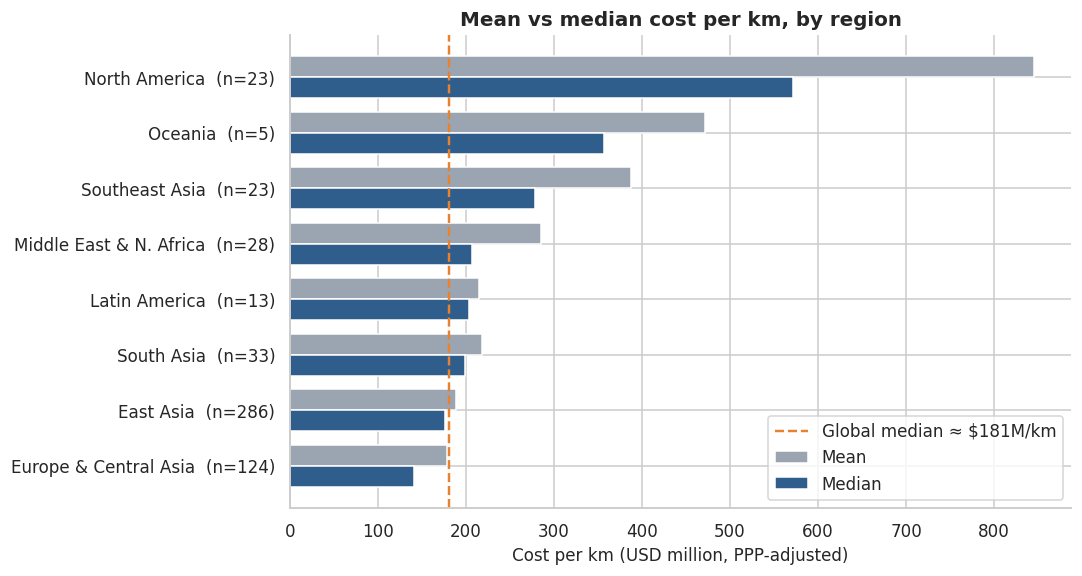

In [29]:
# Chart: mean vs median cost per km, by region – the gap between them exposes the skew
reg = df.groupby("region")["cost_per_km_usd_m"].agg(mean="mean", median="median", n="size").sort_values("median")
g_med = df["cost_per_km_usd_m"].median()

fig, ax = plt.subplots(figsize=(10, 5.4))
y, h = np.arange(len(reg)), 0.38
ax.barh(y + h/2, reg["mean"],   h, color=GREY, label="Mean")
ax.barh(y - h/2, reg["median"], h, color=BLUE, label="Median")
ax.axvline(g_med, color=ORANGE, ls="--", lw=1.6, label=f"Global median ≈ ${g_med:,.0f}M/km")
ax.set_yticks(y); ax.set_yticklabels([f"{r}  (n={n})" for r, n in zip(reg.index, reg["n"])])
ax.set_xlabel("Cost per km (USD million, PPP-adjusted)")
ax.set_title("Mean vs median cost per km, by region")
ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

**Interpretation — central tendency**

**What it shows:** the typical project costs about **\$181M per km** (median), while the mean is **\$233M** — 29 % higher. Mean > median for every cost, size and time variable; the exception is `tunnel_pct`, whose median is 100 % (most projects are fully underground).

**Chart:** in every region the mean sits above the median. The gap is widest in North America (\$845M vs \$571M), where a handful of New York mega-projects pull the average up.

**Takeaway:** use **medians** for benchmarking — the mean overstates the "normal" project. Regional medians run from **\$141M** (Europe & Central Asia) to **\$571M** (North America), a 4× spread.

## 3.2 Variance & standard deviation
Variance and standard deviation are in the variable's own units, so they cannot be compared across columns. The **coefficient of variation (CV = std ÷ mean)** puts every variable on one scale.

In [30]:
spread = pd.DataFrame({
    "variance":  df[num_cols].var(),
    "std dev":   df[num_cols].std(),
    "CV (std ÷ mean)": df[num_cols].std() / df[num_cols].mean(),
    "IQR (Q3 − Q1)": df[num_cols].quantile(.75) - df[num_cols].quantile(.25),
})
spread

,variance,std dev,CV (std ÷ mean),IQR (Q3 − Q1)
cost_per_km_usd_m,"66,674.37",258.21,1.11,105.89
cost_usd_m,"37,707,859.80",6140.67,1.38,4389.27
length_km,512.50,22.64,1.05,22.41
stations,208.37,14.43,1.01,16.00
tunnel_pct,1307.85,36.16,0.48,46.75
duration_years,8.18,2.86,0.50,2.00


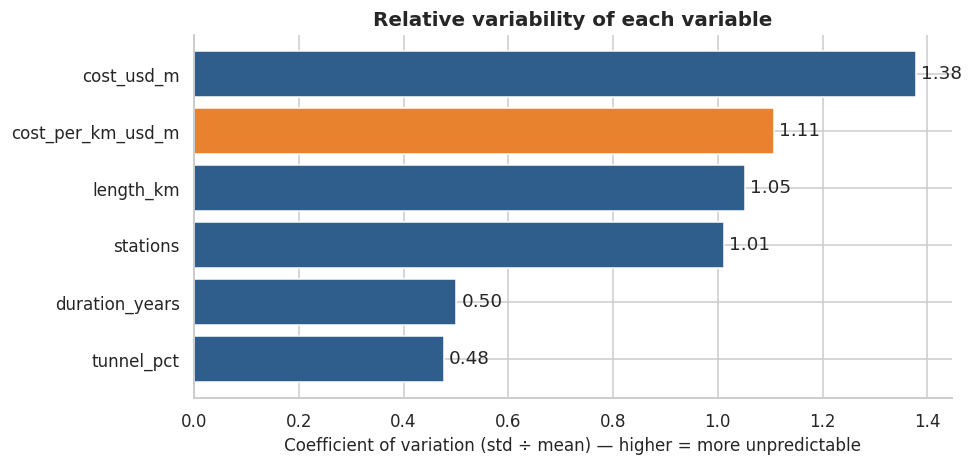

In [31]:
cv = spread["CV (std ÷ mean)"].sort_values()
fig, ax = plt.subplots(figsize=(9, 4.4))
bars = ax.barh(cv.index, cv.values, color=[ORANGE if i == "cost_per_km_usd_m" else BLUE for i in cv.index])
for b, v in zip(bars, cv.values):
    ax.text(v + 0.01, b.get_y() + b.get_height()/2, f"{v:.2f}", va="center")
ax.set_xlabel("Coefficient of variation (std ÷ mean) — higher = more unpredictable")
ax.set_title("Relative variability of each variable")
plt.tight_layout(); plt.show()

**Interpretation — variance & standard deviation**

**What it shows:** the standard deviation of cost per km (\$258M) is *larger than its own mean* (\$233M), a CV of **1.11**. Total project cost (1.38), line length (1.05) and stations (1.01) are equally erratic, while `tunnel_pct` (0.48) and build time (0.50) are comparatively stable.

**Why it matters:** the gap between one project and the next is as big as the average project itself, so a single global "cost per km" is a poor budgeting tool. Benchmarks must be built within comparable groups — the logic behind the budget tool in section 4.3.

**Note:** the IQR is only \$106M (\$135M–\$241M), far narrower than the standard deviation. The spread is created by a thin tail of extreme projects, not by the bulk.

## 3.3 Skewness, kurtosis & outlier detection (IQR / box plot)

In [32]:
shape_stats = pd.DataFrame({
    "skewness":            df[num_cols].skew(),
    "excess kurtosis":     df[num_cols].kurt(),
    "skewness after log":  np.log1p(df[num_cols]).skew(),
    "kurtosis after log":  np.log1p(df[num_cols]).kurt(),
})
shape_stats

,skewness,excess kurtosis,skewness after log,kurtosis after log
cost_per_km_usd_m,8.06,93.47,0.53,3.87
cost_usd_m,6.82,76.98,-0.50,0.37
length_km,3.56,20.23,-0.15,-0.51
stations,3.04,15.28,-0.04,-0.63
tunnel_pct,-1.17,-0.24,-2.12,2.98
duration_years,2.35,9.38,0.37,1.34


In [33]:
def iqr_summary(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return pd.Series({"Q1": q1, "Q3": q3, "lower fence": lo, "upper fence": hi, "outliers": int(((s < lo) | (s > hi)).sum())})

out_tbl = df[["cost_per_km_usd_m", "length_km", "stations", "duration_years"]].apply(iqr_summary).T
out_tbl["% of projects"] = out_tbl["outliers"] / len(df) * 100
out_tbl

,Q1,Q3,lower fence,upper fence,outliers,% of projects
cost_per_km_usd_m,134.87,240.76,-23.97,399.60,49.00,9.16
length_km,6.50,28.91,-27.11,62.51,18.00,3.36
stations,4.00,20.00,-20.00,44.00,15.00,2.80
duration_years,4.00,6.00,1.00,9.00,51.00,9.53


In [34]:
# Which projects are the extreme cost outliers?
df.nlargest(8, "cost_per_km_usd_m")[["country", "city", "line", "length_km", "tunnel_pct", "cost_per_km_usd_m"]].reset_index(drop=True)

,country,city,line,length_km,tunnel_pct,cost_per_km_usd_m
0,United States,New York,East Side Access,2.80,100.00,3928.57
1,United States,New York,Second Avenue Phase 2,2.60,100.00,2457.69
2,United States,New York,Gateway,5.30,100.00,1792.45
3,United States,New York,Second Avenue Phase 1,2.70,100.00,1648.15
4,United States,New York,7 extension,1.60,100.00,1500.00
5,Singapore,Singapore,Circle Line Stage 6,4.00,100.00,1370.12
6,United Kingdom,London,Crossrail,21.00,100.00,888.53
7,United States,Los Angeles,Purple Phase 3,4.20,100.00,857.14


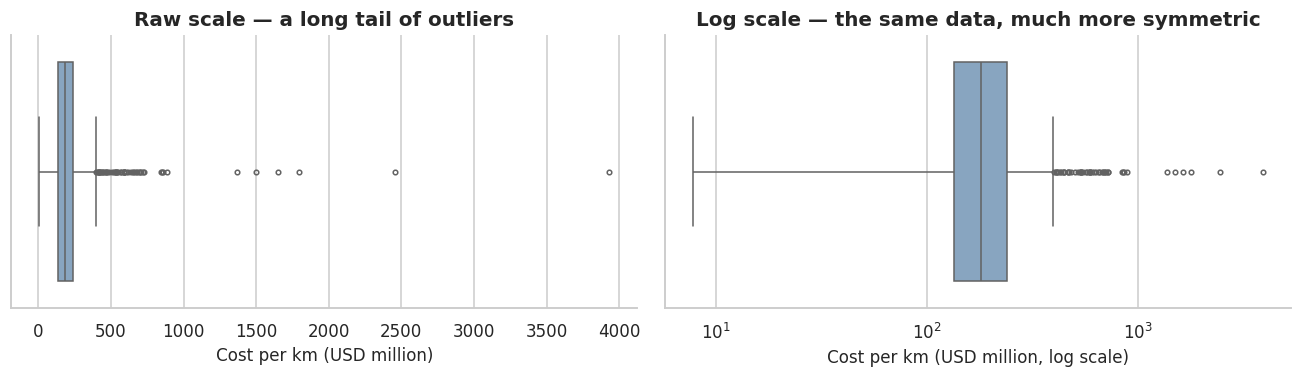

In [35]:
# Box plot: raw scale vs log scale
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
sns.boxplot(x=df["cost_per_km_usd_m"], color="#7FA6C9", fliersize=3, ax=axes[0])
axes[0].set_title("Raw scale — a long tail of outliers"); axes[0].set_xlabel("Cost per km (USD million)")
sns.boxplot(x=df["cost_per_km_usd_m"], color="#7FA6C9", fliersize=3, ax=axes[1]); axes[1].set_xscale("log")
axes[1].set_title("Log scale — the same data, much more symmetric"); axes[1].set_xlabel("Cost per km (USD million, log scale)")
plt.tight_layout(); plt.show()

In [36]:
# Decision on outliers: compare the statistics with and without them
lo, hi = out_tbl.loc["cost_per_km_usd_m", ["lower fence", "upper fence"]]
trimmed = df[df["cost_per_km_usd_m"].between(lo, hi)]
pd.DataFrame({
    "all projects":      df["cost_per_km_usd_m"].agg(["count", "mean", "median", "std"]),
    "outliers removed":  trimmed["cost_per_km_usd_m"].agg(["count", "mean", "median", "std"]),
})

,all projects,outliers removed
count,535.00,486.00
mean,233.12,179.35
median,181.16,172.83
std,258.21,70.32


**Interpretation — skewness, kurtosis & outliers**

**Shape:** cost per km is extremely right-skewed (**skewness 8.1**, excess kurtosis 93) — a long tail of very expensive projects. After a log transform, skewness falls to **0.5**, which is why charts use a log scale and tests are rank-based. Length (3.6), stations (3.0) and duration (2.4) are also right-skewed; `tunnel_pct` is left-skewed (−1.2) because so many lines are fully underground.

**Outliers (IQR rule):** 49 projects (**9.2 %**) cost more than \$400M per km. The top five are all **New York** projects (East Side Access reaches \$3.9B per km, ≈22× the median), followed by Singapore's Circle Line Stage 6, London's Crossrail and Los Angeles' Purple Line Phase 3. All are fully underground and mostly short urban tunnels (1.6–5.3 km, apart from Crossrail's 21 km) — real, documented megaprojects.

**Decision — keep them.** They are genuine, not data errors, and they are exactly the risk a budget planner needs to see. Removing them would cut the mean from \$233M to \$179M and the standard deviation from \$258M to \$70M, hiding that risk. So I keep them and rely on medians, log scales and rank-based tests, which are robust to extremes.

## 3.4 Do the patterns hold up statistically? (hypothesis tests)
Charts suggest; tests quantify. Because cost per km is heavily skewed, I use **non-parametric** tests (Spearman, Mann–Whitney U, Kruskal–Wallis) that do not assume a normal distribution. Significance level α = 0.05.

In [37]:
def cles(a, b):
    """Common-language effect size: probability that a random value from `a` exceeds one from `b`."""
    u = stats.mannwhitneyu(a, b, alternative="two-sided").statistic
    return u / (len(a) * len(b))

# --- Test 1: does a higher tunnel share go with a higher cost per km? (Spearman rank correlation)
rho, p = stats.spearmanr(core["tunnel_pct"], core["cost_per_km_usd_m"])
print(f"T1  Tunnel share vs cost/km          Spearman ρ = {rho:+.2f}  (p = {p:.1e})")

# --- Test 2: underground-heavy (>50% tunnel) vs surface-heavy (≤50%) projects
ug, sf = core.loc[core["tunnel_pct"] > 50, "cost_per_km_usd_m"], core.loc[core["tunnel_pct"] <= 50, "cost_per_km_usd_m"]
p2 = stats.mannwhitneyu(ug, sf).pvalue
print(f"T2  Underground-heavy vs surface-heavy  median ${ug.median():,.0f}M vs ${sf.median():,.0f}M  → {ug.median()/sf.median():.1f}×  (p = {p2:.1e}, P(underground costs more) = {cles(ug, sf):.0%}, n = {len(ug)} vs {len(sf)})")

# --- Test 3: do cost/km differ by region? (Kruskal–Wallis, ≥5 projects per region)
groups = [g["cost_per_km_usd_m"].values for _, g in df.groupby("region") if len(g) >= 5]
h_stat, p3 = stats.kruskal(*groups)
print(f"T3  Differences across regions         Kruskal–Wallis H = {h_stat:.1f}  (p = {p3:.1e})")

# --- Test 4: do longer lines cost less per km?
rho4, p4 = stats.spearmanr(df["length_km"], df["cost_per_km_usd_m"])
print(f"T4  Line length vs cost/km             Spearman ρ = {rho4:+.2f}  (p = {p4:.1e})")

# --- Test 5: has cost/km changed over time?
rho5, p5 = stats.spearmanr(df["midpoint_year"], df["cost_per_km_usd_m"])
print(f"T5  Mid-point year vs cost/km          Spearman ρ = {rho5:+.2f}  (p = {p5:.1e})")

# --- Test 6: India vs the rest of the world (excluding India)
ind, row_ = df.loc[df["country"] == "India", "cost_per_km_usd_m"], df.loc[df["country"] != "India", "cost_per_km_usd_m"]
p6 = stats.mannwhitneyu(ind, row_).pvalue
rng = np.random.default_rng(RANDOM_STATE)
boot = [np.median(rng.choice(ind.values, len(ind))) for _ in range(5000)]
ci = np.percentile(boot, [2.5, 97.5])
print(f"T6  India vs rest of world             median ${ind.median():,.0f}M vs ${row_.median():,.0f}M  (p = {p6:.2f}); India 95% bootstrap CI for the median = ${ci[0]:,.0f}M – ${ci[1]:,.0f}M  (n = {len(ind)})")

# --- Test 7: India vs China
chn = df.loc[df["country"] == "China", "cost_per_km_usd_m"]
p7 = stats.mannwhitneyu(ind, chn).pvalue
print(f"T7  India vs China                     median ${ind.median():,.0f}M vs ${chn.median():,.0f}M  → India {ind.median()/chn.median():.1f}× China  (p = {p7:.1e}, n = {len(ind)} vs {len(chn)})")

# --- Test 8: like-for-like — India vs other SURFACE-HEAVY projects (tunnel ≤ 50 %); India builds mostly elevated lines
sfw = core[core["tunnel_pct"] <= 50]
ind_sf = sfw.loc[sfw["country"] == "India", "cost_per_km_usd_m"]
oth_sf = sfw.loc[sfw["country"] != "India", "cost_per_km_usd_m"]
chn_sf = sfw.loc[sfw["country"] == "China", "cost_per_km_usd_m"]
print(f"T8  India vs other surface-heavy       median ${ind_sf.median():,.0f}M vs ${oth_sf.median():,.0f}M  → {ind_sf.median()/oth_sf.median()-1:+.0%}  (p = {stats.mannwhitneyu(ind_sf, oth_sf).pvalue:.2f}, n = {len(ind_sf)} vs {len(oth_sf)})")
print(f"T9  India vs China (surface-heavy)     median ${ind_sf.median():,.0f}M vs ${chn_sf.median():,.0f}M  → {ind_sf.median()/chn_sf.median()-1:+.0%}  (p = {stats.mannwhitneyu(ind_sf, chn_sf).pvalue:.3f}, n = {len(ind_sf)} vs {len(chn_sf)})")

T1  Tunnel share vs cost/km          Spearman ρ = +0.24  (p = 4.9e-08)
T2  Underground-heavy vs surface-heavy  median $190M vs $140M  → 1.4×  (p = 7.4e-08, P(underground costs more) = 66%, n = 384 vs 126)
T3  Differences across regions         Kruskal–Wallis H = 75.2  (p = 1.3e-13)
T4  Line length vs cost/km             Spearman ρ = -0.05  (p = 2.8e-01)
T5  Mid-point year vs cost/km          Spearman ρ = +0.25  (p = 9.2e-09)


T6  India vs rest of world             median $192M vs $181M  (p = 0.81); India 95% bootstrap CI for the median = $149M – $207M  (n = 29)
T7  India vs China                     median $192M vs $176M  → India 1.1× China  (p = 6.7e-01, n = 29 vs 253)
T8  India vs other surface-heavy       median $185M vs $137M  → +35%  (p = 0.13, n = 26 vs 100)
T9  India vs China (surface-heavy)     median $185M vs $119M  → +55%  (p = 0.000, n = 26 vs 34)


**Interpretation — hypothesis tests**

- **T1 / T2 — Tunnelling matters, moderately.** A higher tunnel share goes with higher cost (ρ = +0.24, p < 0.001). Underground-heavy projects have a median of **\$190M vs \$140M** for surface-heavy ones (**1.4×**), and cost more in 66 % of random pairings.
- **T3 — Geography matters a lot.** Cost per km differs significantly across regions (Kruskal–Wallis H = 75, p < 0.001).
- **T4 — No per-km economies of scale.** Longer lines are *not* significantly cheaper per km (ρ = −0.05, p = 0.28).
- **T5 — Costs are rising.** Later projects cost more per km (ρ = +0.25, p < 0.001).
- **T6 / T7 — India overall looks average.** Median \$192M vs \$181M for the rest of the world (p = 0.81) and vs China's \$176M (p = 0.67). India's 95 % bootstrap interval for its median (\$149M–\$207M) comfortably contains the global median: *no evidence that India is more or less expensive overall.*
- **T8 / T9 — Like-for-like is a different picture.** India mostly builds elevated / surface lines, so the fair comparison is with other surface-heavy projects. India: \$185M vs \$137M elsewhere (+35 %, p = 0.13 — a gap, but not conclusive with only 26 projects) and vs China's surface-heavy lines at \$119M (**+55 %**, p < 0.001; the Indian project is costlier in 80 % of random pairings).

**Reading the p-values:** p < 0.05 means the pattern is unlikely to be chance. Statistical significance is not the same as business importance, so every p-value is shown next to an effect size (ratio or median).

## 3.5 Visual analysis
*Every chart sits in its own cell and is followed by an interpretation: what the chart says, which columns it uses, and the business takeaway.*

---
### A. Univariate analysis — one variable at a time

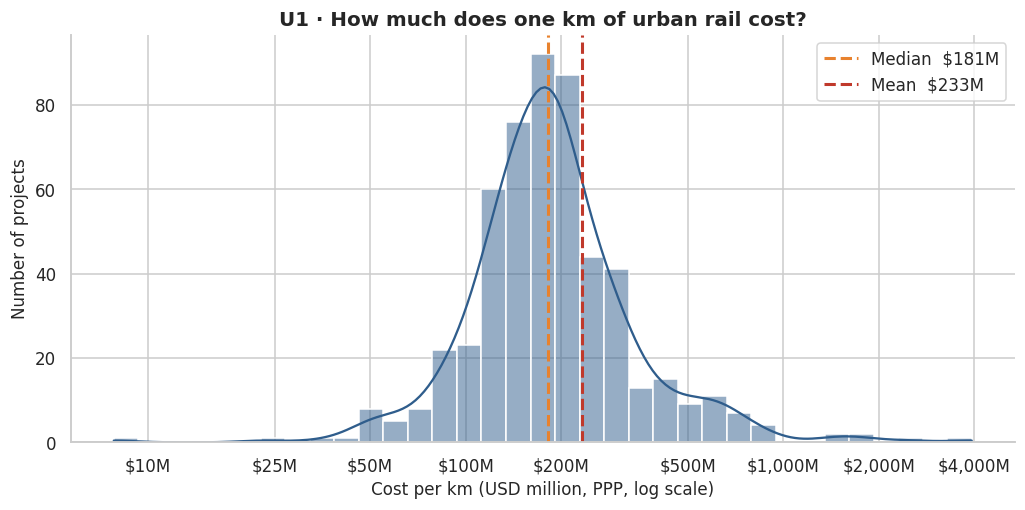

In [38]:
# U1 — Distribution of cost per km
fig, ax = plt.subplots(figsize=(9.5, 4.8))
sns.histplot(df["cost_per_km_usd_m"], log_scale=True, bins=35, kde=True, color=BLUE, ax=ax)
med, mean = df["cost_per_km_usd_m"].median(), df["cost_per_km_usd_m"].mean()
ax.axvline(med,  color=ORANGE, ls="--", lw=2, label=f"Median  ${med:,.0f}M")
ax.axvline(mean, color=RED,    ls="--", lw=2, label=f"Mean  ${mean:,.0f}M")
ticks = [10, 25, 50, 100, 200, 500, 1000, 2000, 4000]
ax.set_xticks(ticks); ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"${v:,.0f}M")); ax.minorticks_off()
ax.set_xlabel("Cost per km (USD million, PPP, log scale)"); ax.set_ylabel("Number of projects")
ax.set_title("U1 · How much does one km of urban rail cost?")
ax.legend(); plt.tight_layout(); plt.show()

**Interpretation — U1 (histogram of `cost_per_km_usd_m`)**

**What it shows:** the distribution of `cost_per_km_usd_m` on a log scale. It is a single hump centred near **\$181M per km** (median), with a long right tail that drags the mean to \$233M.

**Numbers:** 66 % of projects lie between \$100M and \$250M per km; only 10 % are below \$100M, while 9 % exceed \$400M and four exceed \$1.5B.

**Takeaway:** "normal" is a fairly tight band, but the upside risk is large — budgets must plan for the tail.

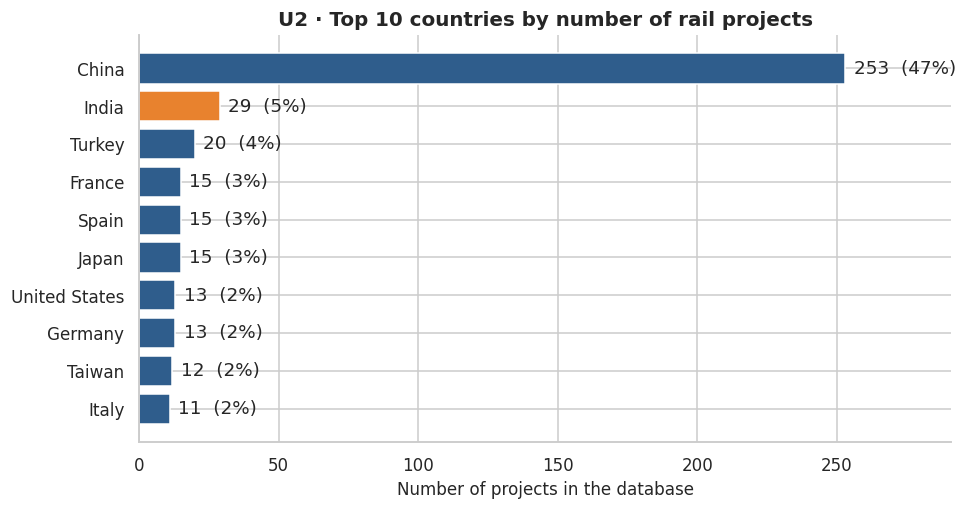

In [39]:
# U2 — Which countries build the most?
top = df["country"].value_counts().head(10)
fig, ax = plt.subplots(figsize=(9, 4.8))
bars = ax.barh(top.index[::-1], top.values[::-1], color=[ORANGE if c == "India" else BLUE for c in top.index[::-1]])
for b, v in zip(bars, top.values[::-1]):
    ax.text(v + 3, b.get_y() + b.get_height()/2, f"{v}  ({v/len(df):.0%})", va="center")
ax.set_xlim(0, top.max() * 1.15); ax.set_xlabel("Number of projects in the database")
ax.set_title("U2 · Top 10 countries by number of rail projects")
plt.tight_layout(); plt.show()

**Interpretation — U2 (bar chart of `country`)**

**What it shows:** project counts by `country`. **China alone contributes 253 of 535 projects (47 %)**; India is second with 29 (5 %), then Turkey (20) and France, Spain and Japan (15 each). The database covers 56 countries and 140 cities but is heavily China-weighted.

**Takeaway:** global averages are largely "Chinese averages". That is why I rely on medians and regions, compare India with China and with the rest of the world separately, and show only countries with at least 5 projects in country rankings.

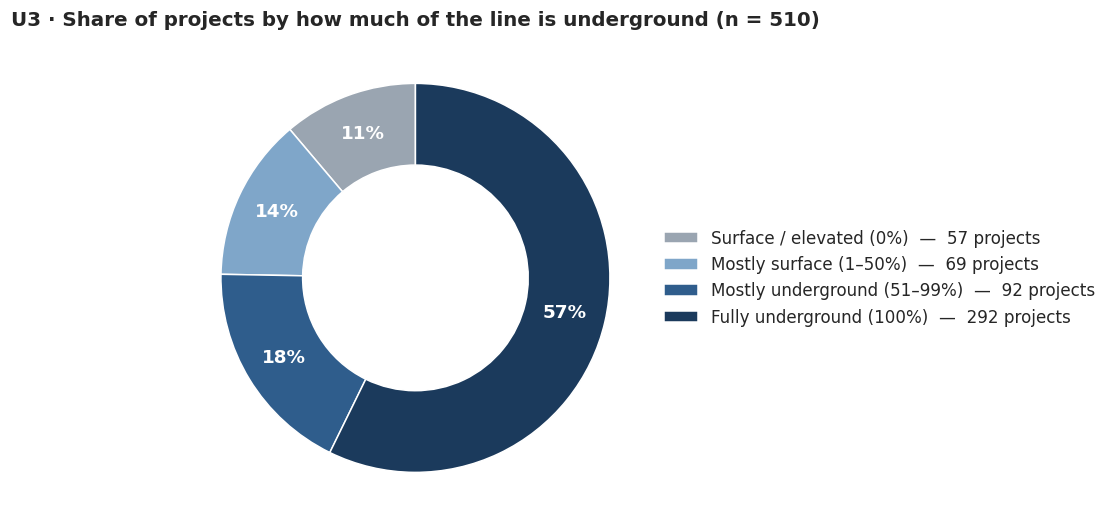

In [40]:
# U3 — How much of the world builds underground?
cats = df["tunnel_category"].cat.categories
share = core["tunnel_category"].value_counts().reindex(cats)
fig, ax = plt.subplots(figsize=(8, 5))
wedges, _, _ = ax.pie(share, autopct="%1.0f%%", startangle=90, pctdistance=0.79, colors=[GREY, "#7FA6C9", BLUE, "#1B3A5C"],
                      wedgeprops=dict(width=0.42, edgecolor="white"), textprops=dict(color="white", fontweight="bold"))
ax.legend(wedges, [f"{c}  —  {n} projects" for c, n in share.items()], loc="center left", bbox_to_anchor=(0.98, 0.5), frameon=False)
ax.set_title(f"U3 · Share of projects by how much of the line is underground (n = {len(core)})")
plt.tight_layout(); plt.show()

**Interpretation — U3 (donut chart of `tunnel_category`)**

**What it shows:** the share of projects by `tunnel_category` (510 projects with real tunnel data). **57 % are fully underground** and 75 % are more than half underground; only 11 % are purely surface / elevated.

**Takeaway:** the database is dominated by dense-city metro lines where going underground is the norm — which is why "is tunnelling the cost driver?" is central. It also shows that elevated lines, India's usual choice, are the minority globally.

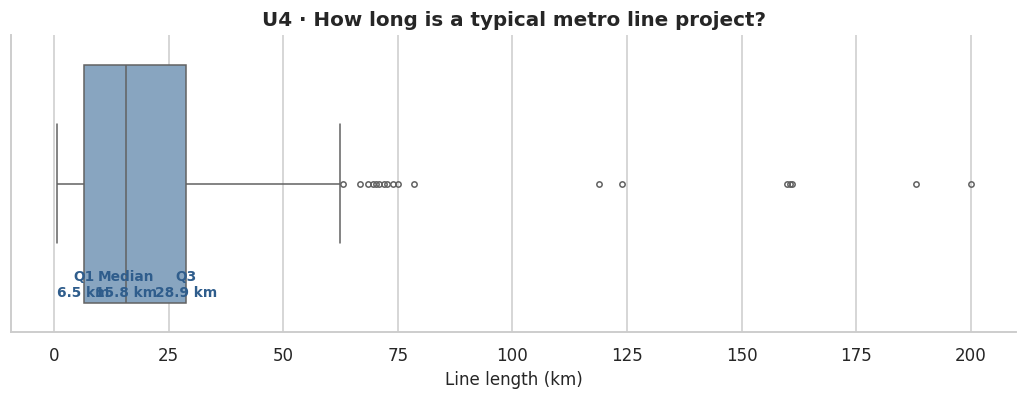

In [41]:
# U4 — Line length
fig, ax = plt.subplots(figsize=(9.5, 3.8))
sns.boxplot(x=df["length_km"], color="#7FA6C9", fliersize=3.5, ax=ax)
q1, q2, q3 = df["length_km"].quantile([.25, .5, .75])
for q, lab in [(q1, "Q1"), (q2, "Median"), (q3, "Q3")]:
    ax.annotate(f"{lab}\n{q:.1f} km", xy=(q, 0.38), ha="center", fontsize=9, color=BLUE, fontweight="bold")
ax.set_xlabel("Line length (km)"); ax.set_title("U4 · How long is a typical metro line project?")
plt.tight_layout(); plt.show()

**Interpretation — U4 (box plot of `length_km`)**

**What it shows:** a box plot of `length_km`. Half of all projects are between **6.5 and 28.9 km**, with a median of **15.8 km**; 37 % are shorter than 10 km. A few giants stretch the whiskers (the longest is 200 km), so the mean (21.5 km) sits above the median.

**Takeaway:** most projects are extensions or single lines, not whole networks. A 3 km tunnel and a 160 km network cannot be judged on total cost alone — hence **cost per km** is the main metric in this analysis.

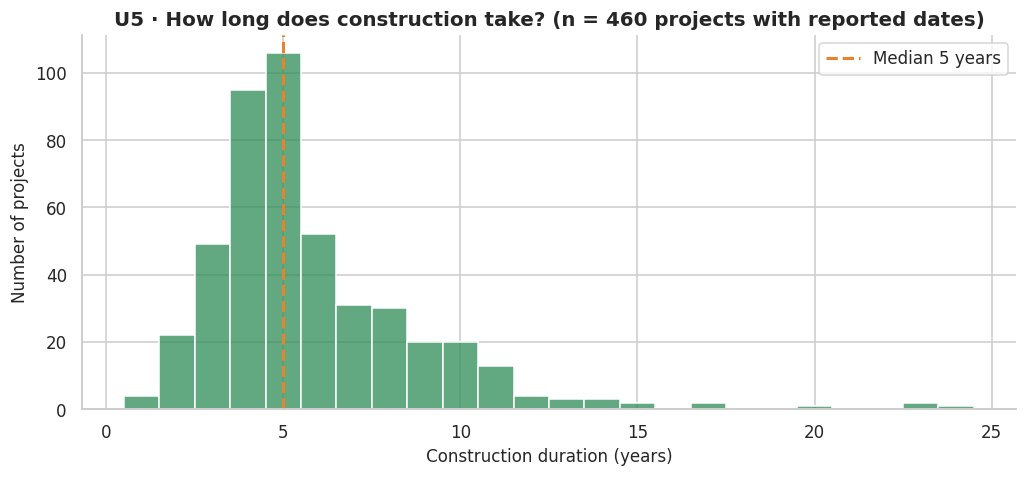

In [42]:
# U5 — Build time (only projects with a reported timeline – imputed values would fake precision)
obs = df.loc[~df["timeline_imputed"], "duration_years"]
fig, ax = plt.subplots(figsize=(9.5, 4.5))
sns.histplot(obs, bins=np.arange(0.5, obs.max() + 1.5, 1), color=GREEN, ax=ax)
ax.axvline(obs.median(), color=ORANGE, ls="--", lw=2, label=f"Median {obs.median():.0f} years")
ax.set_xlabel("Construction duration (years)"); ax.set_ylabel("Number of projects")
ax.set_title(f"U5 · How long does construction take? (n = {len(obs)} projects with reported dates)")
ax.legend(); plt.tight_layout(); plt.show()

**Interpretation — U5 (histogram of `duration_years`)**

**What it shows:** build time (planned or actual) for the 460 projects with reported start and end years. The median is **5 years** (mean 5.8); 71 % finish within 6 years, but 15 % take more than 8 years and the longest takes 24.

**Takeaway:** a typical metro line is a 5-year commitment with a long tail of delayed or phased projects. The 75 projects with imputed timelines are excluded so the chart does not show fake precision.

---
### B. Bivariate analysis — relationships between two variables

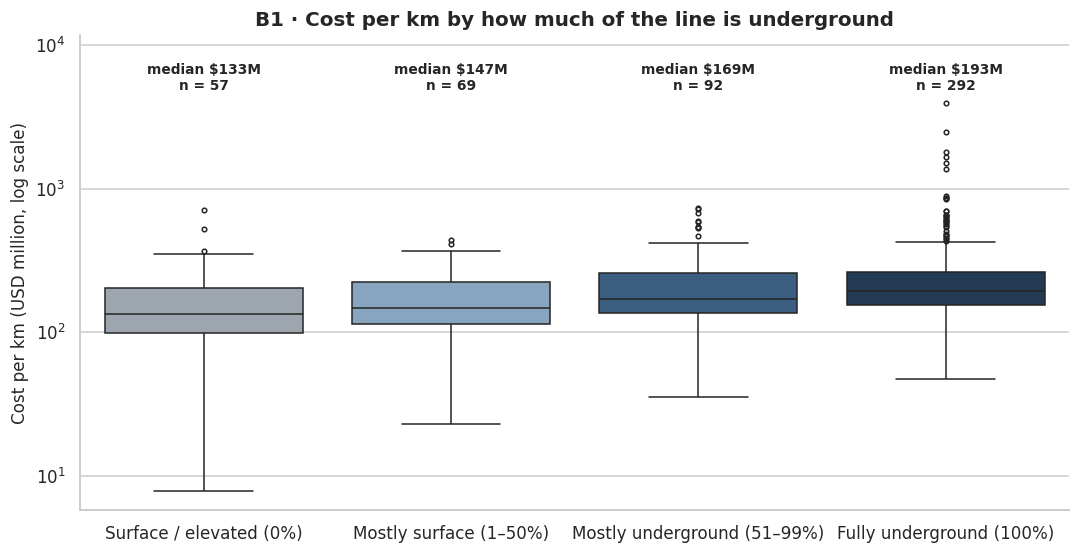

In [43]:
# B1 — Does going underground cost more?
order = list(cats)
fig, ax = plt.subplots(figsize=(10, 5.2))
sns.boxplot(data=core, x="tunnel_category", y="cost_per_km_usd_m", order=order, palette=[GREY, "#7FA6C9", BLUE, "#1B3A5C"], hue="tunnel_category", dodge=False, legend=False, fliersize=3, ax=ax)
ax.set_yscale("log")
meds = core.groupby("tunnel_category", observed=True)["cost_per_km_usd_m"].median()
cnt  = core["tunnel_category"].value_counts()
for i, c in enumerate(order):
    ax.text(i, core["cost_per_km_usd_m"].max() * 1.25, f"median ${meds[c]:,.0f}M\nn = {cnt[c]}", ha="center", fontsize=9, fontweight="bold")
ax.set_ylim(top=core["cost_per_km_usd_m"].max() * 3)
ax.set_xlabel(""); ax.set_ylabel("Cost per km (USD million, log scale)")
ax.set_title("B1 · Cost per km by how much of the line is underground")
plt.tight_layout(); plt.show()

**Interpretation — B1 (box plot: `tunnel_category` vs `cost_per_km_usd_m`)**

**What it shows:** `cost_per_km_usd_m` for each `tunnel_category` (log scale). Cost climbs steadily with tunnelling: median **\$133M** (surface / elevated) → \$147M → \$169M → **\$193M** (fully underground).

**Takeaway:** going underground adds a consistent premium of roughly **+45 % at the median** between the two extremes, but the boxes overlap heavily, so tunnelling alone does not explain cost. Projects above \$1B per km appear only among fully underground lines. This is a *global* comparison — M4 shows the premium is larger *within* a region.

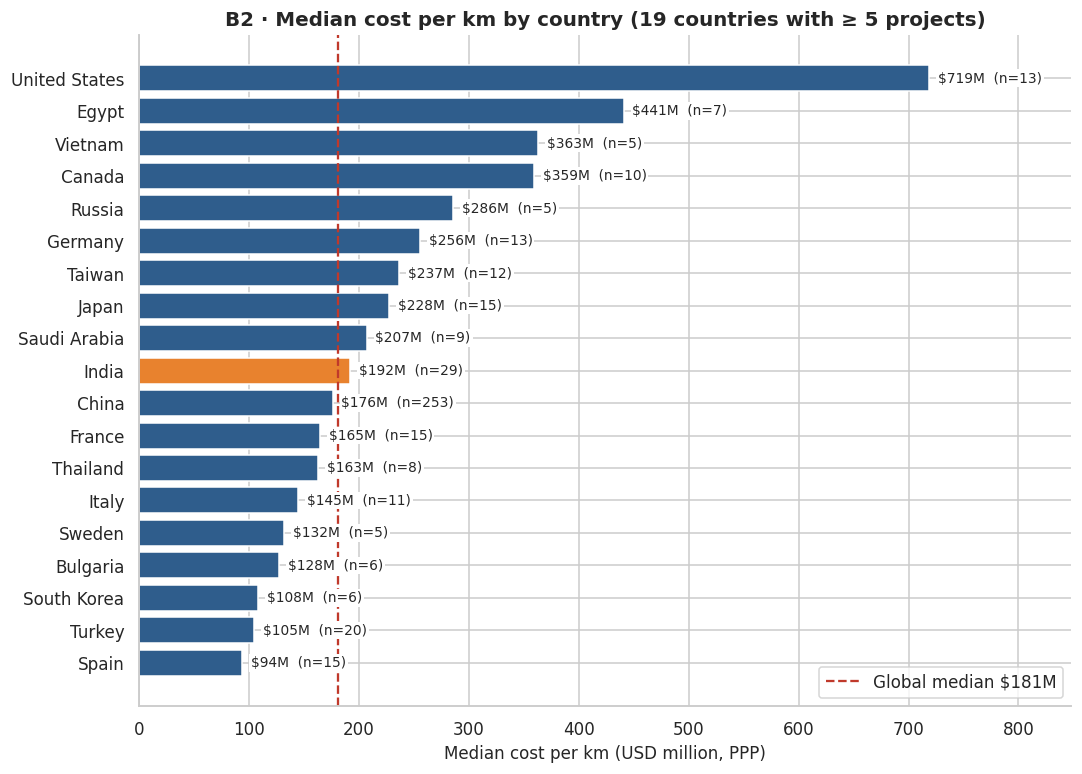

In [44]:
# B2 — Which countries are cheapest and most expensive? (countries with ≥ 5 projects only)
ctry = df.groupby("country")["cost_per_km_usd_m"].agg(median="median", n="size")
ctry = ctry[ctry["n"] >= 5].sort_values("median")
fig, ax = plt.subplots(figsize=(10, 7.2))
bars = ax.barh(ctry.index, ctry["median"], color=[ORANGE if c == "India" else BLUE for c in ctry.index])
for b, (m_, n_) in zip(bars, zip(ctry["median"], ctry["n"])):
    ax.text(m_ + 8, b.get_y() + b.get_height()/2, f"${m_:,.0f}M  (n={n_})", va="center", fontsize=9, bbox=dict(facecolor="white", edgecolor="none", pad=1.2))
ax.axvline(g_med, color=RED, ls="--", lw=1.5, label=f"Global median ${g_med:,.0f}M")
ax.set_xlim(0, ctry["median"].max() * 1.18)
ax.set_xlabel("Median cost per km (USD million, PPP)"); ax.set_title(f"B2 · Median cost per km by country ({len(ctry)} countries with ≥ 5 projects)")
ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

**Interpretation — B2 (bar chart: `country` vs median `cost_per_km_usd_m`)**

**What it shows:** median `cost_per_km_usd_m` for the 19 countries with at least 5 projects. The **United States (\$719M) is about 4× the global median** and 7.6× Spain (\$94M), the cheapest. Low-cost builders — Spain, Turkey (\$105M), South Korea (\$108M), Italy (\$145M) — all build almost entirely underground (85–100 % of their projects), so cheap tunnelling is clearly possible.

**India:** \$192M (n = 29), close to the global median and slightly above China (\$176M, n = 253).

**Caution:** countries with 5–7 projects (Vietnam, Egypt, Russia, Sweden) are indicative only. **Takeaway:** *where* a line is built matters more than any single engineering feature — pointing to procurement, labour, land and governance.

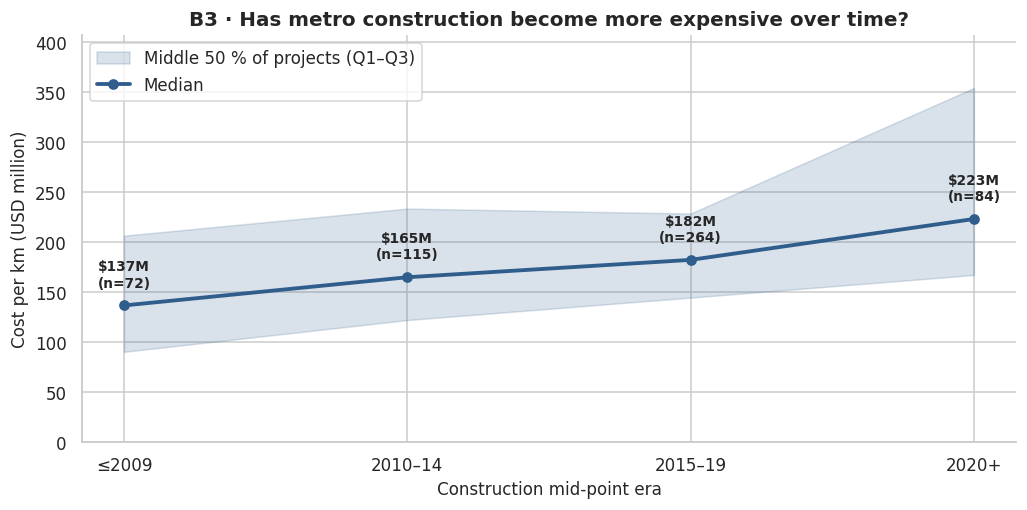

In [45]:
# B3 — Has the cost per km risen over time?
tr = df.groupby("era", observed=True)["cost_per_km_usd_m"].agg(q1=lambda s: s.quantile(.25), median="median", q3=lambda s: s.quantile(.75), n="size")
fig, ax = plt.subplots(figsize=(9.5, 4.8))
x = np.arange(len(tr))
ax.fill_between(x, tr["q1"], tr["q3"], color=BLUE, alpha=0.18, label="Middle 50 % of projects (Q1–Q3)")
ax.plot(x, tr["median"], marker="o", lw=2.5, color=BLUE, label="Median")
for xi, (m_, n_) in enumerate(zip(tr["median"], tr["n"])):
    ax.annotate(f"${m_:,.0f}M\n(n={n_})", (xi, m_), textcoords="offset points", xytext=(0, 12), ha="center", fontsize=9, fontweight="bold")
ax.set_xticks(x); ax.set_xticklabels(tr.index); ax.set_xlabel("Construction mid-point era"); ax.set_ylabel("Cost per km (USD million)")
ax.set_ylim(0, tr["q3"].max() * 1.15); ax.set_title("B3 · Has metro construction become more expensive over time?")
ax.legend(loc="upper left"); plt.tight_layout(); plt.show()

**Interpretation — B3 (line chart: `era` vs `cost_per_km_usd_m`)**

**What it shows:** median cost per km by construction era, with the middle 50 % band. The median rises from **\$137M** (≤2009) to \$165M, \$182M and **\$223M** (2020+) — **+63 %** end to end — and the whole band shifts upward.

**Takeaway:** metro construction is getting costlier (rank correlation +0.25, p < 0.001). Two cautions: 2020+ figures are mostly budgets for planned projects, not final costs, and I found nothing in the data documentation indicating that costs were deflated to constant prices, so part of the rise is probably general inflation. Either way, budgets built on pre-2010 benchmarks will be too low.

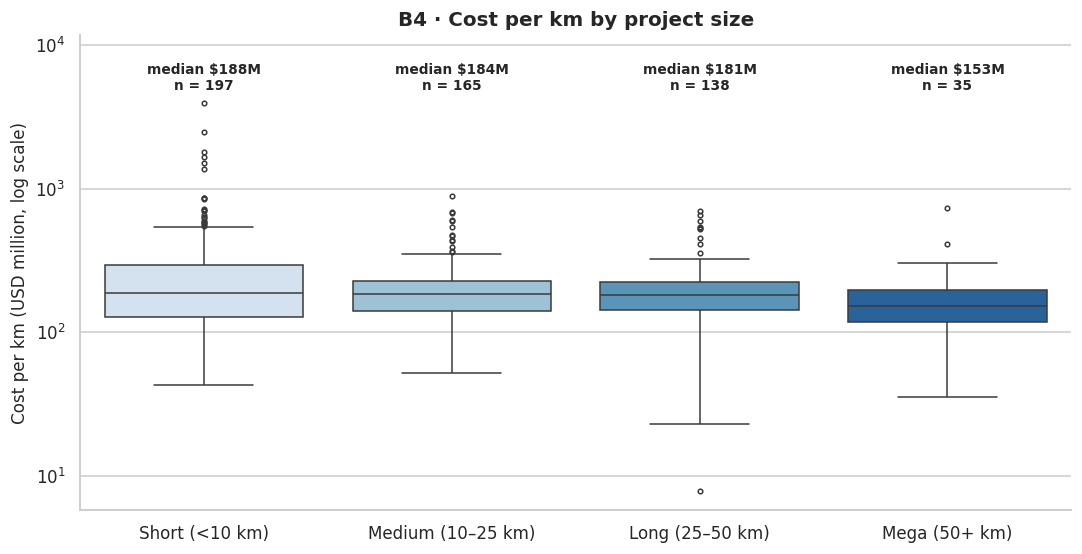

In [46]:
# B4 — Do longer lines get cheaper per km? (economies of scale)
order_l = list(df["length_class"].cat.categories)
fig, ax = plt.subplots(figsize=(10, 5.2))
sns.boxplot(data=df, x="length_class", y="cost_per_km_usd_m", order=order_l, palette="Blues", hue="length_class", dodge=False, legend=False, fliersize=3, ax=ax)
ax.set_yscale("log")
meds = df.groupby("length_class", observed=True)["cost_per_km_usd_m"].median(); cnt = df["length_class"].value_counts()
for i, c in enumerate(order_l):
    ax.text(i, df["cost_per_km_usd_m"].max() * 1.25, f"median ${meds[c]:,.0f}M\nn = {cnt[c]}", ha="center", fontsize=9, fontweight="bold")
ax.set_ylim(top=df["cost_per_km_usd_m"].max() * 3)
ax.set_xlabel(""); ax.set_ylabel("Cost per km (USD million, log scale)"); ax.set_title("B4 · Cost per km by project size")
plt.tight_layout(); plt.show()

**Interpretation — B4 (box plot: `length_class` vs `cost_per_km_usd_m`)**

**What it shows:** `cost_per_km_usd_m` by `length_class`. Medians barely move — \$188M (short), \$184M, \$181M, then \$153M for mega-projects of 50+ km (n = 35) — and the rank correlation between length and cost per km is −0.05 (p = 0.28): **not significant**.

**Takeaway:** there is only a faint hint of scale economies, and only at network scale. Doubling a line's length roughly doubles its price (see M3), so planners should not expect a "bulk discount" per km on longer lines.

---
### C. Multivariate analysis — three or more variables together

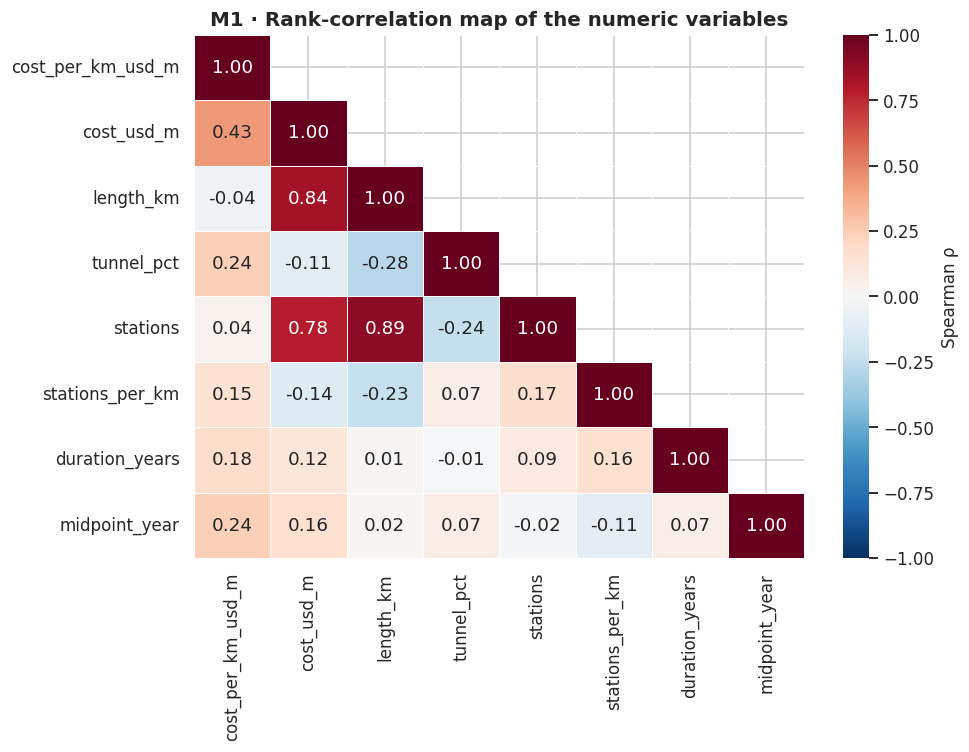

In [47]:
# M1 — Correlation heatmap (Spearman: robust to skew and outliers)
corr_cols = ["cost_per_km_usd_m", "cost_usd_m", "length_km", "tunnel_pct", "stations", "stations_per_km", "duration_years", "midpoint_year"]
corr = core[corr_cols].corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, linewidths=.5, cbar_kws={"label": "Spearman ρ"}, ax=ax)
ax.set_title("M1 · Rank-correlation map of the numeric variables")
plt.tight_layout(); plt.show()

**Interpretation — M1 (heatmap of 8 numeric columns)**

**What it shows:** Spearman rank correlations on the `core` set. The strongest links are structural: total cost with length (**+0.84**) and stations (+0.78), and stations with length (+0.89) — longer lines have more stations and cost more in total, as expected.

**What drives cost *per km*?** Only modest links: tunnel share (+0.24), mid-point year (+0.24), build duration (+0.18) and station density (+0.15); length is about zero (−0.04). Tunnel share is **negatively** linked to length (−0.28): surface lines tend to be longer, which partly masks the tunnelling premium.

**Takeaway:** no single variable explains cost per km — a hint that country and procurement factors (not in the data) matter, as the predictive baseline later confirms.

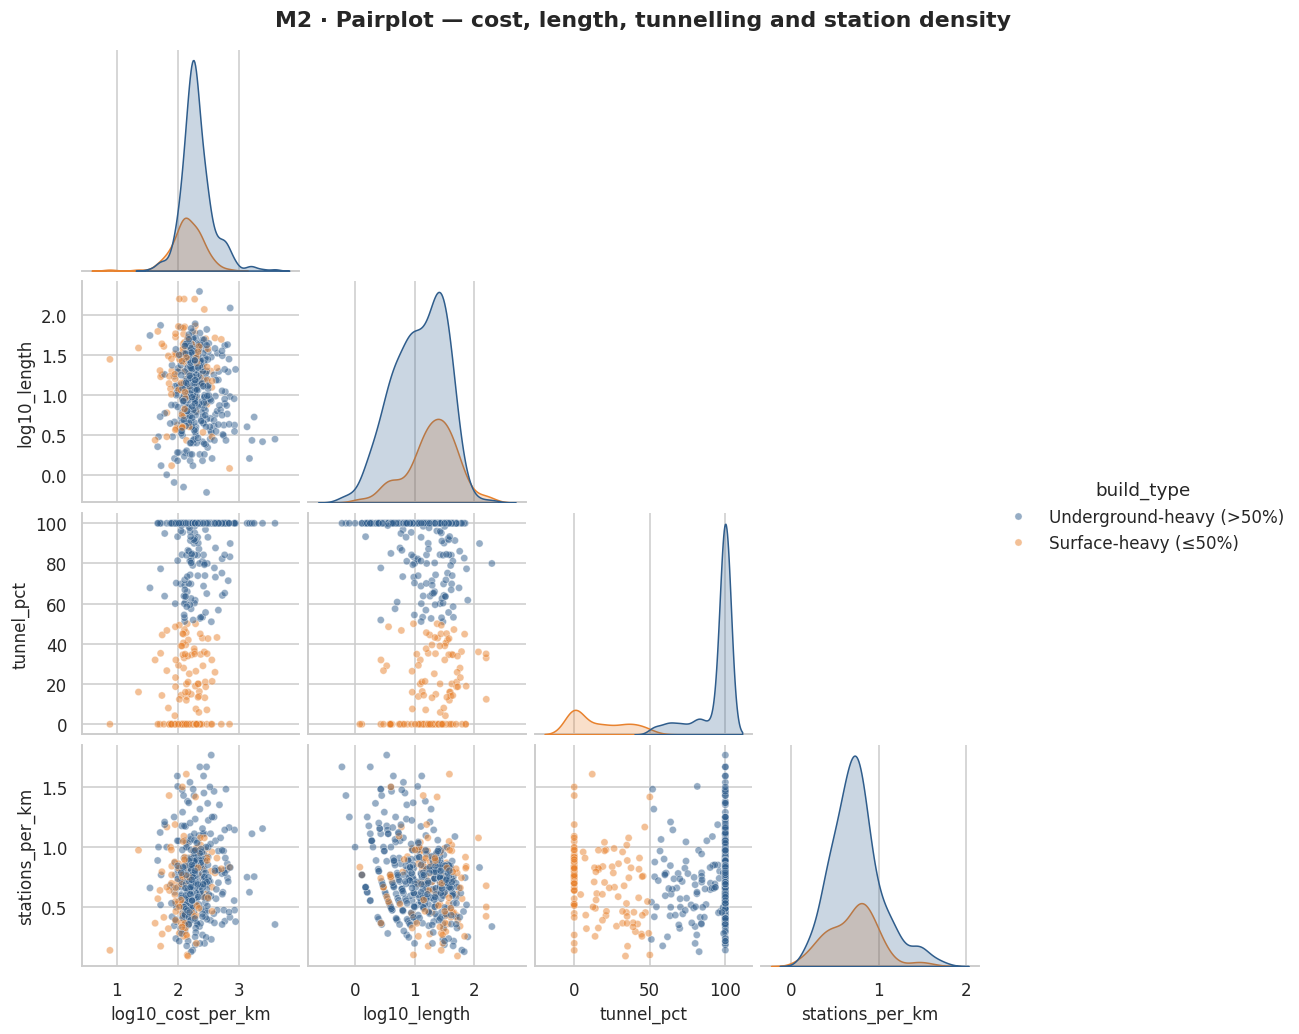

In [48]:
# M2 — Pairplot: cost, size, tunnelling and station density together
pp = core.assign(log10_length=np.log10(core["length_km"]),
                 build_type=np.where(core["tunnel_pct"] > 50, "Underground-heavy (>50%)", "Surface-heavy (≤50%)"))
g = sns.pairplot(pp, vars=["log10_cost_per_km", "log10_length", "tunnel_pct", "stations_per_km"], hue="build_type",
                 palette={"Underground-heavy (>50%)": BLUE, "Surface-heavy (≤50%)": ORANGE},
                 corner=True, diag_kind="kde", plot_kws=dict(alpha=0.5, s=22), height=2.3)
g.figure.suptitle("M2 · Pairplot — cost, length, tunnelling and station density", y=1.02, fontweight="bold")
plt.show()

**Interpretation — M2 (pairplot of 4 variables, coloured by build type)**

**What it shows:** pairwise scatter plots and distributions of four variables (log cost per km, log length, tunnel %, station density), split by build type. Underground-heavy projects (blue) sit slightly higher on cost; surface-heavy projects (orange) are **longer** and cluster at 0 % tunnel.

**Takeaway:** the cloud is wide in every panel — cost per km varies by an order of magnitude for similar length and tunnel share, with no clean linear pattern. That is why simple models can only partly predict cost.

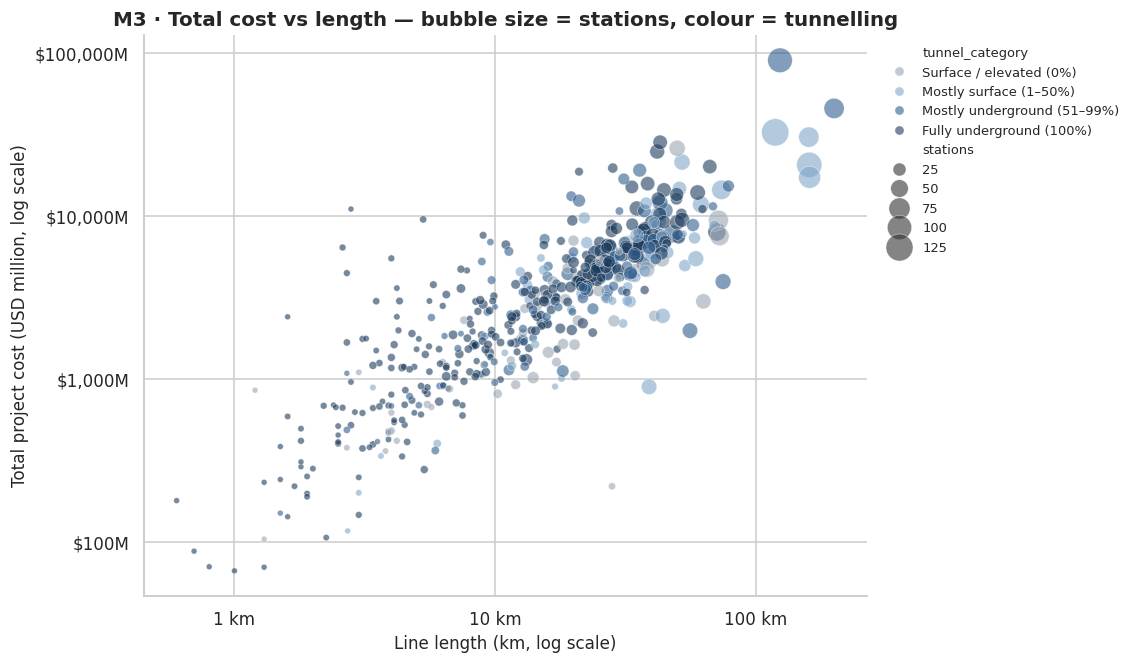

In [49]:
# M3 — Bubble chart: total project cost vs length, sized by stations, coloured by tunnelling
fig, ax = plt.subplots(figsize=(10.5, 6.2))
sns.scatterplot(data=core, x="length_km", y="cost_usd_m", size="stations", sizes=(15, 320), hue="tunnel_category",
                hue_order=list(cats), palette=[GREY, "#7FA6C9", BLUE, "#1B3A5C"], alpha=0.6, edgecolor="white", linewidth=.4, ax=ax)
ax.set_xscale("log"); ax.set_yscale("log")
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f} km"))
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"${v:,.0f}M"))
ax.set_xlabel("Line length (km, log scale)"); ax.set_ylabel("Total project cost (USD million, log scale)")
ax.set_title("M3 · Total cost vs length — bubble size = stations, colour = tunnelling")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False, fontsize=8.5)
plt.tight_layout(); plt.show()

**Interpretation — M3 (bubble chart: `length_km`, `cost_usd_m`, `stations`, `tunnel_category`)**

**What it shows:** total cost (`cost_usd_m`) against `length_km` on log-log axes; bubble size = `stations`, colour = `tunnel_category`. The points form a tight upward diagonal: a log-log slope of **0.94** (R² = 0.72) means total cost rises almost in proportion to length — a line twice as long costs about 1.9× as much.

**Takeaway:** the largest networks (100+ km, big bubbles) sit on the same cost line as small tunnels, so there is little evidence of volume discounts. The vertical scatter around the diagonal — an order of magnitude at a given length — is the unexplained cost that creates budget risk.

tunnel_category,Surface / elevated (0%),Mostly surface (1–50%),Mostly underground (51–99%),Fully underground (100%)
region,,,,
Europe & Central Asia,80.00,67.00,132.00,156.00
East Asia,118.00,124.00,162.00,192.00
Latin America,NaN,155.00,NaN,216.00
South Asia,162.00,199.00,402.00,NaN
Middle East & N. Africa,171.00,216.00,590.00,204.00
Southeast Asia,163.00,247.00,533.00,657.00
North America,NaN,NaN,441.00,619.00
Oceania,NaN,NaN,NaN,843.00


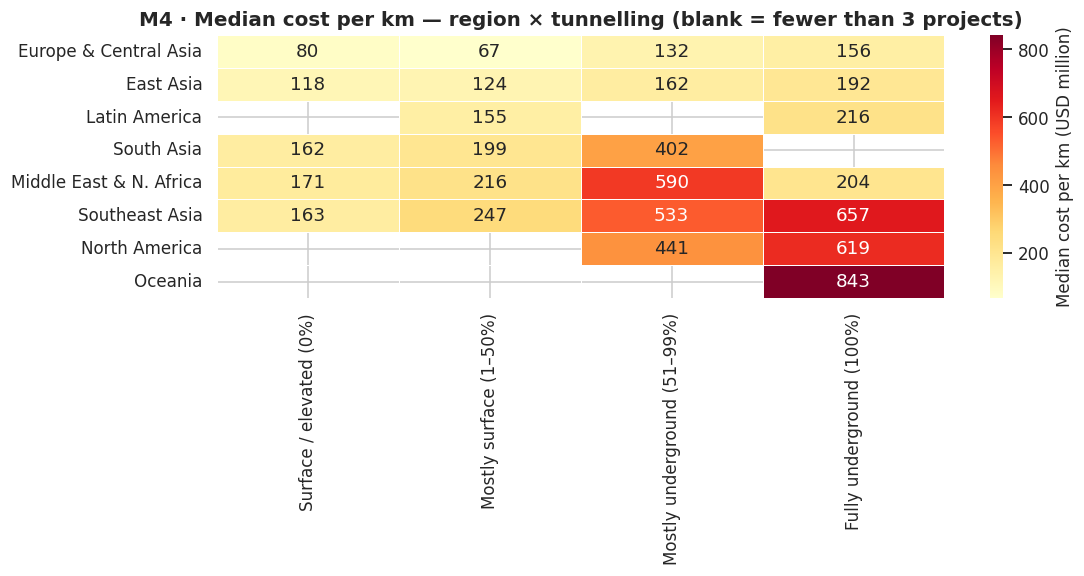

In [50]:
# M4 — Pivot table + heatmap: region × tunnelling (cells with fewer than 3 projects are blanked out)
piv = core.pivot_table(index="region", columns="tunnel_category", values="cost_per_km_usd_m", aggfunc="median", observed=True)
cnt = core.pivot_table(index="region", columns="tunnel_category", values="cost_per_km_usd_m", aggfunc="size", observed=True)
piv = piv.where(cnt >= 3)
piv = piv.loc[piv.mean(axis=1).sort_values().index]
display(piv.round(0))

fig, ax = plt.subplots(figsize=(10.5, 5.4))
sns.heatmap(piv, annot=True, fmt=".0f", cmap="YlOrRd", linewidths=.5, linecolor="white", cbar_kws={"label": "Median cost per km (USD million)"}, ax=ax)
ax.set_xlabel(""); ax.set_ylabel("")
ax.set_title("M4 · Median cost per km — region × tunnelling (blank = fewer than 3 projects)")
plt.tight_layout(); plt.show()

**Interpretation — M4 (pivot-table heatmap: `region` × `tunnel_category` → median `cost_per_km_usd_m`)**

**What it shows:** median cost per km for each region × tunnelling combination (cells with fewer than 3 projects are blank). Where data are sufficient, the broad pattern is **more tunnelling = higher cost** (small cells have exceptions, e.g. the Middle East's fully underground \$204M vs \$590M for mostly underground): East Asia \$118M (surface) → \$192M (fully underground; 23 vs 161 projects, **1.6×**); Southeast Asia \$163M → \$657M and South Asia \$162M → \$402M (mostly underground) — a 2.5–4× premium, although from small groups.

**Takeaway:** this resolves a puzzle in B1. Globally the underground premium looks modest (1.4×) because the cheapest builders (China, Europe) tunnel heavily and pull the underground median down; *within* a region the premium is larger. North America is expensive at every tunnelling level (\$441M–\$619M).

---
### D. Business deep-dive — where does India stand?

In [51]:
# India vs China vs the rest of the world – side-by-side scorecard
scorecard = df.groupby("peer_group").agg(
    projects=("project_id", "size"),
    median_cost_per_km=("cost_per_km_usd_m", "median"),
    median_length_km=("length_km", "median"),
    median_stations_per_km=("stations_per_km", "median"),
).join(core.groupby("peer_group")["tunnel_pct"].median().rename("median_tunnel_pct")
).join(df[~df["timeline_imputed"]].groupby("peer_group")["duration_years"].median().rename("median_build_years"))
scorecard.loc[["India", "China", "Rest of world"]]

,projects,median_cost_per_km,median_length_km,median_stations_per_km,median_tunnel_pct,median_build_years
peer_group,,,,,,
India,29,191.97,24.90,0.84,0.00,6.00
China,253,176.10,22.50,0.66,100.00,4.00
Rest of world,253,195.99,10.50,0.78,100.00,6.00


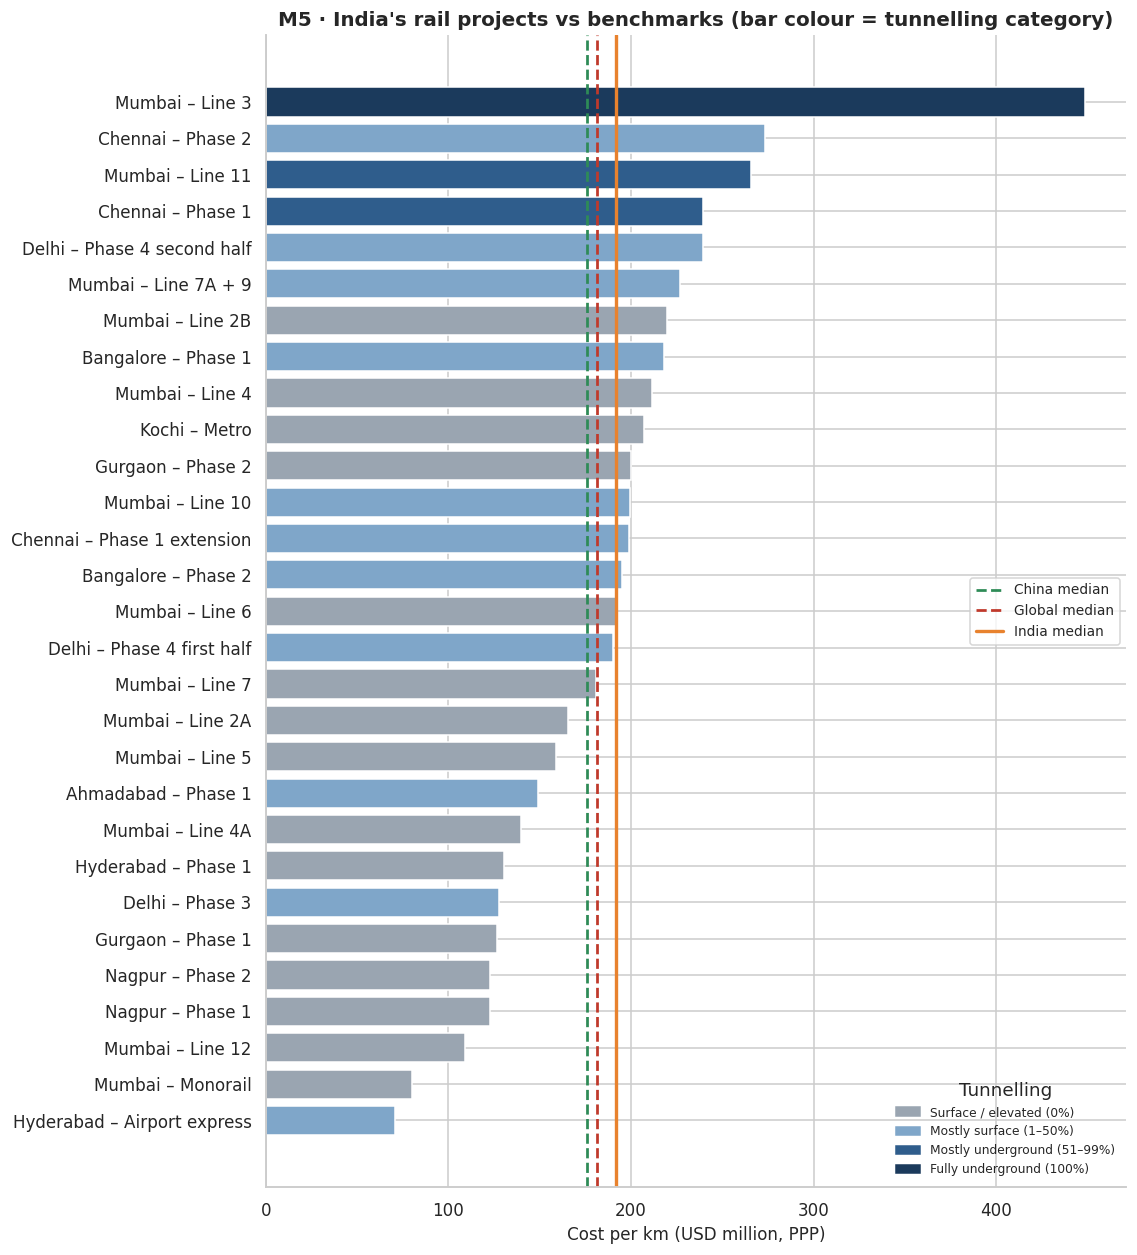

In [52]:
# M5 — Every Indian project vs the benchmarks
ind_df = df[df["country"] == "India"].copy()
ind_df["label"] = ind_df["city"] + " – " + ind_df["line"].str.slice(0, 28)
ind_df = ind_df.sort_values("cost_per_km_usd_m")
pal = dict(zip(cats, [GREY, "#7FA6C9", BLUE, "#1B3A5C"]))
fig, ax = plt.subplots(figsize=(10.5, 0.33 * len(ind_df) + 2))
ax.barh(ind_df["label"], ind_df["cost_per_km_usd_m"], color=ind_df["tunnel_category"].map(pal).astype(str))
ax.axvline(df.loc[df["country"] == "China", "cost_per_km_usd_m"].median(), color=GREEN, ls="--", lw=1.8, label="China median")
ax.axvline(g_med, color=RED, ls="--", lw=1.8, label="Global median")
ax.axvline(ind_df["cost_per_km_usd_m"].median(), color=ORANGE, ls="-", lw=2.2, label="India median")
ax.set_xlabel("Cost per km (USD million, PPP)")
ax.set_title("M5 · India's rail projects vs benchmarks (bar colour = tunnelling category)")
handles = [plt.Rectangle((0, 0), 1, 1, color=pal[c]) for c in cats]
leg1 = ax.legend(handles, cats, title="Tunnelling", loc="lower right", fontsize=8, frameon=False); ax.add_artist(leg1)
ax.legend(loc="center right", fontsize=9)
plt.tight_layout(); plt.show()

**Interpretation — M5 (bar chart: every Indian project's `cost_per_km_usd_m`, coloured by `tunnel_category`)**

**What it shows:** every Indian project's cost per km (n = 29), coloured by tunnelling, against the India median (\$192M, orange), global median (\$181M, red) and China median (\$176M, green). The cheapest are elevated lines — Hyderabad Airport Express (\$71M), Mumbai Monorail (\$80M), Nagpur (≈\$123M) — and the dearest is **Mumbai Line 3 (\$449M, fully underground, ≈2.5× the global median)**. Chennai's lines sit at \$199M (Phase 1 extension), \$240M (Phase 1) and \$274M (Phase 2), roughly 10–50 % above the global median with 26–53 % of their length underground.

**Scorecard (table above):** India builds *longer* projects (median 24.9 km vs 10.5 km in the rest of the world; China 22.5), with *denser* stations (0.84 per km vs China's 0.66), and takes **6 years vs China's 4** (reported timelines).

**Takeaway:** India is average overall, yet almost all its lines are elevated — the type that is *cheaper* elsewhere (surface-heavy median \$140M). Like-for-like (T9), Indian surface-heavy lines cost 55 % more than China's. The opportunity is cost and schedule of elevated construction.

---
# Stage 4 — Documentation, Insights & Presentation

## 4.1 Summary of findings (plain English)
I analysed **535 urban-rail projects in 56 countries** (data up to January 2021) to answer a budgeting question: *what should a kilometre of metro cost?*

- A typical km costs about **\$181M** (PPP-adjusted). A few mega-projects pull the average up to \$233M; New York's East Side Access reaches **\$3.9B per km**.
- **Where** a line is built matters most: North America's median is **\$571M**, Europe's **\$141M**.
- **Tunnelling** adds a real premium (1.4× globally, 1.6× or more within a region); costs per km are **rising over time**; longer lines get **no per-km discount**.
- **India** sits at the global median (\$192M) overall, but because it mostly builds elevated lines, its like-for-like cost is higher — **+55 % versus China's** surface-heavy lines — and its projects take longer (6 vs 4 years).

## 4.2 Key insights
**1 · Cost per km is wildly uneven — benchmark with the median, not the mean.** Median \$181M vs mean \$233M; skewness 8.1; 66 % of projects fall in a \$100M–\$250M band, yet 9 % exceed \$400M and the top five are all in New York (up to \$3.9B per km, ≈22× the median).

**2 · Geography dominates cost.** Regional medians range from \$141M (Europe & Central Asia) to \$571M (North America); the United States (\$719M) is 7.6× Spain (\$94M). The difference between regions is highly significant (p < 0.001) and is the single strongest feature in the predictive baseline.

**3 · Tunnelling is a real but partly hidden driver.** Globally, underground-heavy lines cost 1.4× surface-heavy ones (\$190M vs \$140M, p < 0.001). Within East Asia, where samples are large, fully underground lines cost 1.6× surface lines (\$192M vs \$118M). The global figure looks smaller only because the cheapest builders (China, Spain, Turkey) tunnel heavily.

**4 · Metro construction is getting more expensive.** Median cost per km rose from \$137M (≤2009) to \$223M (2020+), +63 % (ρ = +0.25, p < 0.001). Part of this is likely inflation and the newest figures are budgets, but the direction is clear.

**5 · Longer lines get no per-km discount.** Length vs cost per km is uncorrelated (ρ = −0.05, p = 0.28) and total cost scales almost one-for-one with length (log-log slope 0.94, R² = 0.72).

**6 · India is average overall — but expensive like-for-like.** India's median (\$192M) is statistically indistinguishable from the world (\$181M) and China (\$176M). However, 26 of its 29 projects are mostly surface / elevated, where one expects *lower* costs: they cost **+55 % vs China's** comparable lines (p < 0.001) and +35 % vs the rest of the world (directional, p = 0.13). Indian projects also take longer (6 vs 4 years). Chennai's Phase 1 and Phase 2 sit at \$240M and \$274M per km.

## 4.3 Types of analysis

### 1 · Descriptive analysis — *what happened?*
Covered in sections 3.1–3.3 and the univariate charts: the typical cost (median **\$181M per km**), the spread (CV = 1.11), the shape (skewness 8.1), project size, tunnelling mix and build time.

### 2 · Diagnostic analysis — *why did it happen?*
Covered in sections 3.4 and the bivariate / multivariate charts: geography, tunnelling, project size and time were each tested statistically. The pivot heatmap (M4) separates the *tunnelling* effect from the *country* effect.

### 3 · Predictive analysis — *what is likely to happen?*
A deliberately simple **baseline model** that predicts cost per km from information available *before* construction: line length, tunnel share, station density, start era and region. It is a baseline, not a production model; its job is to show how much of the cost can be explained by project characteristics alone.

In [53]:
# Predictive baseline: log10(cost per km) from pre-construction characteristics
model_df = df.copy()
model_df["log10_length"] = np.log10(model_df["length_km"])
num_feats = ["log10_length", "tunnel_pct", "stations_per_km", "midpoint_year", "rail_flag"]
cat_feats = ["region"]
X, y = model_df[num_feats + cat_feats], model_df["log10_cost_per_km"]

prep = ColumnTransformer([("num", StandardScaler(), num_feats),
                          ("cat", OneHotEncoder(handle_unknown="ignore"), cat_feats)])
models = {
    "Baseline (always predict the median)": DummyRegressor(strategy="median"),
    "Linear regression":                    LinearRegression(),
    "Random forest":                        RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=RANDOM_STATE, n_jobs=-1),
}
cv5 = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

rows = []
for name, mdl in models.items():
    res = cross_validate(Pipeline([("prep", prep), ("model", mdl)]), X, y, cv=cv5, scoring=["r2", "neg_mean_absolute_error"])
    mae = -res["test_neg_mean_absolute_error"].mean()
    rows.append({"model": name, "R² (5-fold CV)": res["test_r2"].mean(), "MAE (log10 units)": mae, "typical error (× factor)": 10 ** mae})
pd.DataFrame(rows).set_index("model")

,R² (5-fold CV),MAE (log10 units),typical error (× factor)
model,,,
Baseline (always predict the median),-0.01,0.18,1.52
Linear regression,0.40,0.15,1.41
Random forest,0.31,0.15,1.43


Hold-out R² (random forest, 20 % unseen projects): 0.39


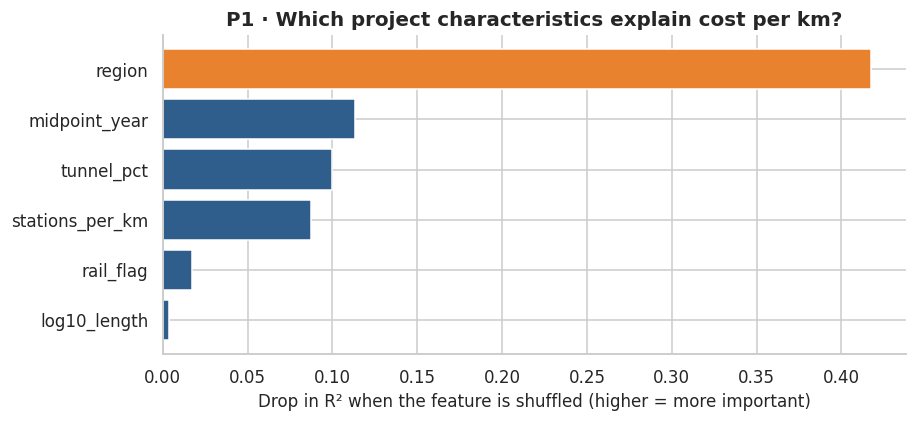

In [54]:
# What drives the predictions? Permutation importance on a hold-out set
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
rf = Pipeline([("prep", prep), ("model", RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=RANDOM_STATE, n_jobs=-1))]).fit(X_tr, y_tr)
pi = permutation_importance(rf, X_te, y_te, n_repeats=30, random_state=RANDOM_STATE, scoring="r2")
imp = pd.Series(pi.importances_mean, index=X.columns).sort_values()
print(f"Hold-out R² (random forest, 20 % unseen projects): {rf.score(X_te, y_te):.2f}")

fig, ax = plt.subplots(figsize=(8.5, 4))
ax.barh(imp.index, imp.values, color=[ORANGE if i == imp.idxmax() else BLUE for i in imp.index])
ax.set_xlabel("Drop in R² when the feature is shuffled (higher = more important)")
ax.set_title("P1 · Which project characteristics explain cost per km?")
plt.tight_layout(); plt.show()

**Interpretation — predictive baseline**

**Result:** simple project characteristics explain a meaningful but limited share of cost per km. The linear model reaches **R² ≈ 0.40** in 5-fold cross-validation (random forest 0.31; 0.39 on the hold-out set), versus ≈ 0 for the "always predict the median" baseline. In practical terms a typical prediction is off by a factor of **×1.4** (×1.5 for the baseline) — the model narrows the uncertainty, it does not remove it.

**What drives it (chart P1):** `region` is by far the most important feature (about 4× the next one), followed by start era, tunnel share and station density. Line length adds nothing once these are known — consistent with the statistics above.

**Takeaway:** roughly 60 % of the variation comes from factors **not in this dataset** (procurement model, geology, land acquisition, scope, governance). The honest message for decision-makers: use project characteristics to set a *benchmark range*, then investigate any gap — do not treat the model as a quote.

### 4 · Prescriptive analysis — *what should we do?*
Insight is only useful if it changes a decision. The function below turns the benchmark into a **budget sanity-check tool**: give it a region, line length and tunnel share, and it returns the budget range implied by *comparable* real projects. If a proposed budget is supplied, it says whether it is low, in line, or high.

In [55]:
def benchmark_budget(region, length_km, tunnel_pct, proposed_total_musd=None, min_comparables=10):
    """Budget range (USD million, PPP) for a planned line, based on comparable projects."""
    tcat = pd.cut([tunnel_pct], bins=[-0.1, 0, 50, 99.99, 100], labels=cats)[0]
    pool = core[(core["region"] == region) & (core["tunnel_category"] == tcat)]
    scope = f"{region} · {tcat}"
    if len(pool) < min_comparables:                                   # too few local comparables → widen the pool
        pool = core[core["tunnel_category"] == tcat]
        scope = f"Worldwide · {tcat}  (only {len(core[(core['region'] == region) & (core['tunnel_category'] == tcat)])} comparables in {region})"
    q = pool["cost_per_km_usd_m"].quantile([.25, .5, .75])
    out = pd.DataFrame({"cost per km (USD M)": q.values, f"budget for {length_km:g} km (USD M)": q.values * length_km},
                       index=["Low  (P25)", "Benchmark  (P50)", "High  (P75)"]).round(0)
    print(f"Comparable projects: {len(pool)}  →  {scope}")
    if proposed_total_musd is not None:
        per_km = proposed_total_musd / length_km
        pct = stats.percentileofscore(pool["cost_per_km_usd_m"], per_km)
        ordinal = lambda n: f"{n}{'th' if 10 <= n % 100 <= 20 else {1: 'st', 2: 'nd', 3: 'rd'}.get(n % 10, 'th')}"
        verdict = "unusually LOW — check scope / risk allowance" if pct < 25 else "HIGH — needs justification" if pct > 75 else "in line with comparable projects"
        print(f"Proposed ${proposed_total_musd:,.0f}M = ${per_km:,.0f}M per km → {ordinal(int(round(pct)))} percentile → {verdict}")
    return out

# Example 1: a 30 km, mostly-elevated line in South Asia
benchmark_budget("South Asia", length_km=30, tunnel_pct=10, proposed_total_musd=7500)

Comparable projects: 12  →  South Asia · Mostly surface (1–50%)
Proposed $7,500M = $250M per km → 92nd percentile → HIGH — needs justification


,cost per km (USD M),budget for 30 km (USD M)
Low (P25),180.00,5395.00
Benchmark (P50),199.00,5973.00
High (P75),224.00,6716.00


In [56]:
# Example 2: a 15 km fully-underground line in Europe
benchmark_budget("Europe & Central Asia", length_km=15, tunnel_pct=100, proposed_total_musd=2000)

Comparable projects: 92  →  Europe & Central Asia · Fully underground (100%)


Proposed $2,000M = $133M per km → 40th percentile → in line with comparable projects


,cost per km (USD M),budget for 15 km (USD M)
Low (P25),114.00,1716.00
Benchmark (P50),156.00,2346.00
High (P75),251.00,3760.00


In [57]:
# Example 3: the same 15 km underground line in North America — same engineering, very different benchmark
benchmark_budget("North America", length_km=15, tunnel_pct=100)

Comparable projects: 17  →  North America · Fully underground (100%)


,cost per km (USD M),budget for 15 km (USD M)
Low (P25),444.00,6667.00
Benchmark (P50),619.00,9278.00
High (P75),1500.00,"22,500.00"


**Interpretation — budget tool**

**Example 1:** a 30 km mostly-elevated South Asian line (12 comparable projects) benchmarks at **\$5.4B–\$6.7B** (median \$6.0B). A proposed \$7.5B (\$250M per km) lands at the 92nd percentile, so the tool flags it *HIGH — needs justification*.

**Example 2:** a 15 km underground line in Europe benchmarks at \$1.7B–\$3.8B; a \$2.0B proposal is *in line* (40th percentile).

**Example 3:** the same 15 km line in North America benchmarks at **\$6.7B–\$22.5B** — a median of \$9.3B, about 4× Europe's \$2.3B, with a very wide range that shows how uncertain budgets are there.

**Why it matters:** it turns the analysis into a repeatable screening tool a planner or consultant can run in minutes. It is a first-pass check, not a substitute for a detailed estimate.

## 4.4 Recommendations / decision support
1. **Benchmark against comparables, not averages.** Check a proposed budget against projects of the same region and tunnelling share (P25–P75 range) using the budget tool; require justification above P75 and a scope review below P25.
2. **Price the underground premium explicitly.** Within a region, going underground typically adds 1.6× or more. Where geology and land allow, evaluating elevated / at-grade options early can save the most money.
3. **Learn from low-cost builders.** Spain, Turkey, South Korea and Italy deliver largely underground lines at \$94M–\$145M per km. Their procurement, design standardisation and contractor competition deserve a structured case study.
4. **Add an escalation buffer to new budgets.** The median cost per km for 2020+ projects is 63 % above that of pre-2010 projects; benchmarks built on old projects will under-estimate.
5. **For India: attack elevated-line cost and schedule.** Elevated lines should be the cheapest to build, yet they cost more than China's equivalents and take longer. Compare unit costs per km of viaduct, stations and systems, and test whether faster schedules lower cost (build time and cost per km are positively correlated, ρ = +0.18).
6. **Do not expect savings from building longer.** Per-km cost does not fall with length, so phasing decisions should be made on demand and risk, not on assumed scale economies.

## 4.5 Limitations (what this analysis can and cannot say)
- **Estimates, not outturns.** 53 % of cost figures come from official plans and 36 % from media reports; the database does not show final costs, so overruns cannot be measured.
- **Time trend caveat.** PPP conversion adjusts for price levels *between countries*; I found nothing indicating costs were deflated to constant prices, so the rise over time mixes real cost growth and inflation. The data end in January 2021 and the newest projects are budgets.
- **Sample imbalance.** China is 47 % of projects; several countries have only 5–7 projects, and only 5 projects are in Oceania.
- **Imputed values.** 25 tunnel shares, 75 timelines, 11 station counts and 1 cost were imputed (all flagged); tunnel analyses use only real values.
- **Correlation is not causation.** Region effects bundle together labour costs, procurement, geology and governance — none of which are measured here.
- **Rail flag.** The `rail_flag` column's exact definition is uncertain even to the dataset's author, so it is used only as a minor model feature.

## 4.6 Future enhancements
- **Larger, more recent data** — the source is a snapshot up to January 2021; refreshing it with newer project costs would show the post-2021 inflation effect.
- **Better modelling** — add country-level effects (mixed-effects regression) to separate *country* from *tunnelling* properly; add confidence intervals to the benchmark tool.
- **Outturn vs plan** — where final costs are available, analyse cost *overruns*, not just estimates.
- **Dashboard** — publish the cleaned data as an interactive Power BI / Tableau benchmark dashboard so planners can filter by region, tunnelling and size.
- **Automation** — convert the cleaning stage into a reusable Python script/pipeline that runs on every new data release.

## 4.7 Conclusion
This project turned a messy real-world dataset — with text-typed numbers, pasted-in summary rows, hidden zeros and contradicting columns — into a clean, validated table (its cleaned mean and median match the source's own summary rows) and then into evidence a decision-maker can use.

The central finding is that **how much a metro costs depends more on *where* it is built than on how it is built**, that tunnelling adds a real premium that a global average hides, that costs are rising, and that longer lines do not get cheaper per km. India sits at the global median overall but pays more than comparable elevated lines elsewhere, especially versus China — a clear, testable target for cost and schedule improvement.

Beyond charts, the project delivers a **benchmark tool** that converts the findings into a budget sanity-check, and an honest list of limitations — the combination of rigour, clarity and business framing that a consulting or analytics team looks for.

## Appendix — export the clean dataset
The cleaned table (with all derived columns and imputation flags) can be saved and reused, for example as the data source of a Power BI / Tableau dashboard.

In [58]:
df.to_csv("transit_cost_clean.csv", index=False)
print(f"Saved transit_cost_clean.csv  →  {df.shape[0]} rows × {df.shape[1]} columns")
# In Google Colab, uncomment the next two lines to download the file:
# from google.colab import files
# files.download("transit_cost_clean.csv")

Saved transit_cost_clean.csv  →  535 rows × 32 columns
